# Claim-type analysis, sample round (taxonomy v0.8)

**Goal:** repeat the cross-model claim-type analysis on the research samples in `samples/` under taxonomy v0.8: FORECAST limited to quantitatively measurable outcomes, PREDICTION for discrete future events (yellow), POSITIONING limited to exposure actually held (orange), SENTIMENT for market participants' beliefs (cyan), strict RECOMMENDATION, a wider VALUATION, and counterfactuals as VIEW.

**Pipeline** (run from the repo root):

```
.venv\Scripts\python.exe scripts\run_samples.py
.venv\Scripts\python.exe scripts\build_claims_csv.py --runs-root outputs\samples_v08 --texts-dir outputs\samples_v08\inputs --no-gold --pivot-model opus --out outputs\samples_v08\claims_analysis
```

1. `run_samples.py` strips the metadata header from each sample (kept in `summary.json` as `source_metadata`), runs haiku, sonnet and opus with no few-shot example, and writes `outputs/samples_v08/<doc>/<model>/` plus `<doc>/models_list.mmd`, the three maps side by side in list view.
2. `build_claims_csv.py` flattens the valid maps into `claims_all.csv` and `claims_exclusions.csv`.

**Differences from the first round:**

- There is no gold. Alignment clusters pivot on the **opus** run of each sample, so "agreement" means agreement with opus; pairwise agreement for all three model pairs is computed in §2.
- One run per sample and model, so rows are not dominated by one document.
- Probes are regex heuristics that estimate whether a field *could* be filled; they are not extractions.

## 0. Setup

In [ ]:
import json
import re
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import SVG, display
from mermaid import Mermaid

from incolor.argumentation.evaluate import match_statements
from incolor.argumentation.writer import load_argument_map

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUNS_DIR = ROOT / "outputs" / "samples_v08"
DATA_DIR = RUNS_DIR / "claims_analysis"
JSON_COLUMNS = [
    "evidence_ids", "evidence_texts", "roles", "argument_ids", "argument_summaries", "argument_core_types",
    "doc_authors", "doc_asset_classes",
]
TYPES = [
    "RECOMMENDATION", "VALUATION", "FORECAST", "PREDICTION", "POSITIONING", "SENTIMENT", "VIEW", "DATA_POINT",
    "OBSERVATION",
]
MODELS = ["haiku", "sonnet", "opus"]
PIVOT_MODEL = "opus"


def _parse_json(value):
    return json.loads(value) if isinstance(value, str) and value else []


claims = pd.read_csv(DATA_DIR / "claims_all.csv", encoding="utf-8-sig")
for col in JSON_COLUMNS:
    claims[col] = claims[col].map(_parse_json)
claims["evidence"] = claims["evidence_texts"].map(" | ".join)
claims["text"] = claims["statement"] + " || " + claims["evidence"]
exclusions = pd.read_csv(DATA_DIR / "claims_exclusions.csv", encoding="utf-8-sig")

# Short labels keep tables readable; the full sample name stays in `doc`.
DOCS = sorted(claims["doc"].unique())
LABEL = {doc: (doc[:40] + "…") if len(doc) > 41 else doc for doc in DOCS}
claims["label"] = claims["doc"].map(LABEL)

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 200)
print(f"{len(claims)} statements from {claims['run_id'].nunique()} runs over {len(DOCS)} samples")
claims.groupby(["label", "model"]).size().unstack("model", fill_value=0).reindex(columns=MODELS, fill_value=0)

746 statements from 11 runs over 4 samples


model,haiku,sonnet,opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0,35,108
Beam_yields_up__Scotty,120,23,125
BofA_Liquid_Insight_-_France_risks_for_E…,45,21,42
BofA_Sept_FOMC_-_hike_or_bond_spike,85,25,117


In [3]:
SHOW = ["label", "model", "statement_id", "claim_type", "modality", "modality_cue", "statement"]


def of_type(claim_type, df=None):
    df = claims if df is None else df
    return df[df["claim_type"] == claim_type]


def probe(df, patterns, col="statement"):
    """One boolean column per named regex (case-insensitive) matched against ``col``."""
    return pd.DataFrame(
        {name: df[col].str.contains(p, case=False, regex=True, na=False) for name, p in patterns.items()},
        index=df.index,
    )


def fill_rates(df, patterns, by="model", col="statement"):
    """Share of rows matching each probe, per group (fields as rows)."""
    return probe(df, patterns, col).groupby(df[by]).mean().round(2).T


def first_match(df, patterns, col="statement"):
    """Per row, the first text matched by each probe: a preview of what the field would hold."""
    return pd.DataFrame(
        {name: df[col].str.extract(f"({p})", flags=re.IGNORECASE)[0] for name, p in patterns.items()}, index=df.index
    )


def by_model(df, col):
    """Row-normalised distribution of ``col`` per model."""
    table = pd.crosstab(df["model"], df[col], normalize="index").round(2)
    return table.reindex([m for m in MODELS if m in table.index])


def boundary(claim_type, df=None):
    """Aligned rows in clusters typed ``claim_type`` by at least one run and something else by another."""
    df = claims if df is None else df
    aligned = df.dropna(subset=["cluster_id"])
    clusters = aligned.loc[aligned["claim_type"] == claim_type, "cluster_id"].unique()
    sub = aligned[aligned["cluster_id"].isin(clusters)]
    mixed = sub.groupby("cluster_id")["claim_type"].transform("nunique") > 1
    return sub[mixed].sort_values(["cluster_id", "model"])


def boundary_summary(claim_type, df=None):
    """In clusters touched by ``claim_type``: how often each other type was assigned instead."""
    rows = boundary(claim_type, df)
    return rows.loc[rows["claim_type"] != claim_type, "claim_type"].value_counts()


# One row per (statement, argument, role), with the type of that argument's core claim.
memberships = claims[["run_id", "model", "doc", "statement_id", "claim_type", "roles"]].explode("roles")
memberships = memberships.dropna(subset=["roles"]).reset_index(drop=True)
memberships = memberships.assign(
    role=memberships["roles"].map(lambda r: r["role"]),
    argument_id=memberships["roles"].map(lambda r: r["argument_id"]),
    core_type=memberships["roles"].map(lambda r: r["core_type"]),
).drop(columns="roles")

## 1. Runs: success, cost and structure

One row per sample and model from `summary.json`, including failed runs that never reached the CSV.

In [4]:
runs = pd.DataFrame([json.loads(p.read_text(encoding="utf-8")) for p in sorted(RUNS_DIR.glob("*/*/summary.json"))])
runs["label"] = runs["doc"].map(lambda d: LABEL.get(d, d[:40]))
RUN_COLS = [
    "label", "model", "ok", "attempts", "seconds", "cost_usd", "src_chars", "arguments", "statements", "evidence",
    "edges", "isolated", "max_chain", "exclusions",
]
failed = runs[~runs["ok"].fillna(False).astype(bool)]
print(f"{len(runs)} runs, {len(failed)} without a valid map")
if len(failed):
    display(failed.reindex(columns=["label", "model", "attempts", "errors", "issue_codes", "error"]))
runs[[c for c in RUN_COLS if c in runs]].sort_values(["label", "model"])

12 runs, 1 without a valid map


,label,model,attempts,errors,issue_codes,error
0,BC_FX_Views_-_Structural_JPY_weakness_un…,haiku,3,2,{'EVIDENCE_NOT_VERBATIM': 2},NaN


,label,model,ok,attempts,seconds,cost_usd,src_chars,arguments,statements,evidence,edges,isolated,max_chain,exclusions
0,BC_FX_Views_-_Structural_JPY_weakness_un…,haiku,False,3,959.6,0.1624,29201,23,77,70,17,5,4,9
1,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,True,2,676.2,2.3609,29201,19,108,108,16,2,4,10
2,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,True,2,86.0,0.3348,29201,7,35,36,5,1,4,2
3,Beam_yields_up__Scotty,haiku,True,1,419.4,0.0620,15726,21,120,103,6,11,2,25
4,Beam_yields_up__Scotty,opus,True,1,439.1,1.2833,15726,30,125,100,15,11,3,23
5,Beam_yields_up__Scotty,sonnet,True,1,30.1,0.1176,15726,8,23,28,2,5,3,1
6,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,True,2,337.2,0.0560,20494,9,45,34,6,1,3,25
7,BofA_Liquid_Insight_-_France_risks_for_E…,opus,True,1,202.4,0.6032,20494,11,42,44,9,0,3,5
8,BofA_Liquid_Insight_-_France_risks_for_E…,sonnet,True,1,25.7,0.0864,20494,5,21,23,2,1,2,0
9,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,True,2,458.1,0.0770,18849,26,85,89,20,5,6,14


In [5]:
# Per model: totals and medians. stmts_per_1k normalises for sample length.
runs["stmts_per_1k"] = runs["statements"] / runs["src_chars"] * 1000
agg = runs.groupby("model").agg(
    runs=("doc", "size"),
    valid=("ok", "sum"),
    cost_usd=("cost_usd", "sum"),
    median_seconds=("seconds", "median"),
    mean_attempts=("attempts", "mean"),
    median_stmts=("statements", "median"),
    median_stmts_per_1k=("stmts_per_1k", "median"),
    median_args=("arguments", "median"),
    median_edges=("edges", "median"),
    median_isolated=("isolated", "median"),
).reindex(MODELS).round(2)
display(agg)
# Validation issues that triggered repairs, summed over runs.
pd.DataFrame(runs.set_index("model")["issue_codes"].dropna().apply(pd.Series)).groupby(level=0).sum().T

,runs,valid,cost_usd,median_seconds,mean_attempts,median_stmts,median_stmts_per_1k,median_args,median_edges,median_isolated
model,,,,,,,,,,
haiku,4,3,0.36,438.75,2.00,81.0,3.57,22.0,11.5,5.0
sonnet,4,4,0.62,28.75,1.25,24.0,1.26,7.5,3.0,1.5
opus,4,4,6.51,557.65,1.50,112.5,4.95,24.5,15.5,5.5


model,haiku,opus,sonnet
EVIDENCE_NOT_VERBATIM,2.0,0.0,0.0
EXCLUSION_NOT_VERBATIM,2.0,0.0,0.0
EVIDENCE_UNUSED,0.0,0.0,5.0


### Observations

**Scope.** 4 samples × 3 models; 11 of 12 runs are valid. Haiku on BC_FX failed after 3 attempts (2 `EVIDENCE_NOT_VERBATIM` errors remained), so BC_FX has only sonnet and opus. One run per cell, so treat model differences as indicative.

| Model | Cost | Median time | Median stmts | Stmts per 1k chars | Median edges | Exclusions logged per run |
|---|---|---|---|---|---|---|
| haiku | $0.36 | 439 s | 81 | 3.6 | 11.5 | 9–25 |
| sonnet | $0.62 | 29 s | 24 | 1.3 | 3.0 | 0–2 |
| opus | $6.51 (87% of $7.49) | 558 s | 113 | 5.0 | 15.5 | 5–23 |

- **The main difference between models is granularity, not typing.**
  - Opus extracts about 4–5× more statements than sonnet at about 10× the cost, and builds the most connected maps.
  - Sonnet is fast and compact, but logs almost no exclusions. It drops sentences silently rather than recording them, which goes against the "list each omitted claim sentence" rule.
- **Repairs were needed in 6 of 12 runs** (mean attempts: haiku 2.0, opus 1.5, sonnet 1.25). The issue codes shown are from the final attempt only.

## 2. Side-by-side model maps

`run_samples.py` writes `outputs/samples_v08/<doc>/models_list.mmd`: haiku, sonnet and opus as three columns in list view (arguments stacked in order, no links), coloured by core-claim type (PREDICTION yellow, POSITIONING orange, SENTIMENT cyan). Open a `.mmd` file to preview it with the Mermaid extension, or set `DOC` below to render one inline.

In [8]:
comparisons = sorted(RUNS_DIR.glob("*/models_list.mmd"))
for path in comparisons:
    print(path.relative_to(RUNS_DIR).as_posix())

DOC = DOCS[0]
path = RUNS_DIR / DOC / "models_list.mmd"
if path.exists():
    diagram = path.read_text(encoding="utf-8")

    graph = Mermaid(diagram)
    display(SVG(data=graph.svg_response.content))

BC_FX_Views_-_Structural_JPY_weakness_unchanged/models_list.mmd
Beam_yields_up__Scotty/models_list.mmd
BofA_Liquid_Insight_-_France_risks_for_EUR/models_list.mmd
BofA_Sept_FOMC_-_hike_or_bond_spike/models_list.mmd


MermaidError: Mermaid API Error [414]: HTTP 414 Error

Details: <html>
<head><title>414 Request-URI Too Large</title></head>
<body>
<center><h1>414 Request-URI Too Large</h1></center>
<hr><center>nginx/1.30.5</center>
</body>
</html>


## 3. Overview and model invariance

Questions: do the models agree on the *type* of the same statement under v0.8? Which pairs of types are still confused? Do PREDICTION and SENTIMENT take load off FORECAST and VIEW?

In [ ]:
display(pd.crosstab(claims["model"], claims["claim_type"], normalize="index").round(2).reindex(index=MODELS, columns=TYPES, fill_value=0))
# Type mix per sample (all models pooled): which documents drive each type?
pd.crosstab(claims["label"], claims["claim_type"], normalize="index").round(2).reindex(columns=TYPES, fill_value=0)

claim_type,RECOMMENDATION,VALUATION,FORECAST,PREDICTION,POSITIONING,SENTIMENT,VIEW,DATA_POINT,OBSERVATION
model,,,,,,,,,
haiku,0.05,0.02,0.04,0.06,0.03,0.04,0.48,0.14,0.14
sonnet,0.06,0.02,0.09,0.05,0.02,0.01,0.56,0.17,0.03
opus,0.03,0.02,0.05,0.06,0.03,0.03,0.55,0.14,0.09


claim_type,RECOMMENDATION,VALUATION,FORECAST,PREDICTION,POSITIONING,SENTIMENT,VIEW,DATA_POINT,OBSERVATION
label,,,,,,,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0.00,0.01,0.03,0.01,0.01,0.01,0.67,0.16,0.09
Beam_yields_up__Scotty,0.11,0.02,0.00,0.04,0.05,0.03,0.45,0.16,0.13
BofA_Liquid_Insight_-_France_risks_for_E…,0.02,0.06,0.00,0.03,0.06,0.08,0.47,0.16,0.12
BofA_Sept_FOMC_-_hike_or_bond_spike,0.00,0.00,0.15,0.13,0.00,0.02,0.55,0.09,0.06


In [ ]:
display(pd.crosstab(claims["claim_type"], claims["modality"], normalize="index").round(2).reindex(TYPES))
pd.crosstab(memberships["claim_type"], memberships["role"]).reindex(TYPES)

modality,ASSERTED,HEDGED,SPECULATIVE
claim_type,,,
RECOMMENDATION,1.00,0.00,0.00
VALUATION,0.21,0.71,0.07
FORECAST,0.32,0.34,0.34
PREDICTION,0.56,0.28,0.16
POSITIONING,0.87,0.13,0.00
SENTIMENT,0.79,0.21,0.00
VIEW,0.50,0.35,0.15
DATA_POINT,1.00,0.00,0.00
OBSERVATION,1.00,0.00,0.00


role,catalysts,conditions,core_claim,qualifiers,rationale,risks,supporting
claim_type,,,,,,,
RECOMMENDATION,0,1,28,0,0,0,3
VALUATION,0,0,9,0,0,0,11
FORECAST,0,1,14,4,0,0,28
PREDICTION,0,20,26,2,0,1,17
POSITIONING,0,0,0,0,21,2,2
SENTIMENT,0,1,0,0,21,0,4
VIEW,8,15,106,36,0,41,281
DATA_POINT,0,0,0,0,112,0,0
OBSERVATION,0,0,0,0,79,0,0


In [ ]:
# Pairwise agreement between every two models on each sample, via the same statement matcher as the CSV.
# Matching is slow (difflib), so results are cached; delete pairwise.csv after re-running the models.
pairwise_path = DATA_DIR / "pairwise.csv"
if pairwise_path.exists():
    pairwise = pd.read_csv(pairwise_path, encoding="utf-8-sig")
else:
    rows = []
    for doc in DOCS:
        maps = {m: load_argument_map(p) for m in MODELS if (p := RUNS_DIR / doc / m / "argument_map.yaml").exists()}
        for a, b in combinations([m for m in MODELS if m in maps], 2):
            mapping = match_statements(maps[a], maps[b])
            sa, sb = {s.id: s for s in maps[a].statements}, {s.id: s for s in maps[b].statements}
            pairs_ = [(sa[x], sb[y]) for x, y in mapping.items()]
            rows.append({
                "doc": doc,
                "pair": f"{a}-{b}",
                "matched": len(mapping),
                "stmt_overlap_f1": 2 * len(mapping) / (len(sa) + len(sb)) if sa or sb else None,
                "type_agreement": sum(x.claim_type == y.claim_type for x, y in pairs_) / len(pairs_) if pairs_ else None,
                "modality_agreement": sum(x.modality == y.modality for x, y in pairs_) / len(pairs_) if pairs_ else None,
            })
    pairwise = pd.DataFrame(rows)
    pairwise.to_csv(pairwise_path, index=False, encoding="utf-8-sig")
pairwise["label"] = pairwise["doc"].map(LABEL)
display(pairwise.groupby("pair")[["stmt_overlap_f1", "type_agreement", "modality_agreement"]].agg(["mean", "min"]).round(2))
pairwise.pivot(index="label", columns="pair", values="type_agreement").round(2)

stmt_overlap_f1       type_agreement       modality_agreement  \
                        mean   min           mean   min               mean   
pair                                                                         
haiku-opus              0.76  0.65           0.85  0.84               0.93   
haiku-sonnet            0.34  0.11           0.80  0.67               0.91   
sonnet-opus             0.39  0.25           0.91  0.89               0.87   

                    
               min  
pair                
haiku-opus    0.91  
haiku-sonnet  0.79  
sonnet-opus   0.80

pair,haiku-opus,haiku-sonnet,sonnet-opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,NaN,NaN,0.90
Beam_yields_up__Scotty,0.84,1.00,0.91
BofA_Liquid_Insight_-_France_risks_for_E…,0.86,0.74,0.89
BofA_Sept_FOMC_-_hike_or_bond_spike,0.86,0.67,0.94


In [ ]:
# Agreement with the opus pivot, by model and by pivot type.
aligned = claims.dropna(subset=["cluster_id"])
aligned = aligned[aligned["run_id"] != aligned["cluster_pivot"]]
agrees = aligned["claim_type"] == aligned["cluster_pivot_claim_type"]
summary = pd.DataFrame({
    "aligned_share": claims.loc[claims["model"] != PIVOT_MODEL, "cluster_id"].notna().groupby(claims["model"]).mean(),
    "type_agreement": agrees.groupby(aligned["model"]).mean(),
    "modality_agreement": (aligned["modality"] == aligned["cluster_pivot_modality"]).groupby(aligned["model"]).mean(),
}).round(2)
display(summary)
print("Type stability by pivot type:")
agrees.groupby(aligned["cluster_pivot_claim_type"]).agg(["mean", "size"]).reindex(TYPES).round(2)

,aligned_share,type_agreement,modality_agreement
model,,,
haiku,0.81,0.85,0.95
sonnet,0.85,0.91,0.86


Type stability by pivot type:


,mean,size
cluster_pivot_claim_type,,
RECOMMENDATION,0.93,15
VALUATION,0.75,8
FORECAST,0.77,13
PREDICTION,0.75,20
POSITIONING,0.69,13
SENTIMENT,0.80,10
VIEW,0.92,146
DATA_POINT,0.88,41
OBSERVATION,0.83,24


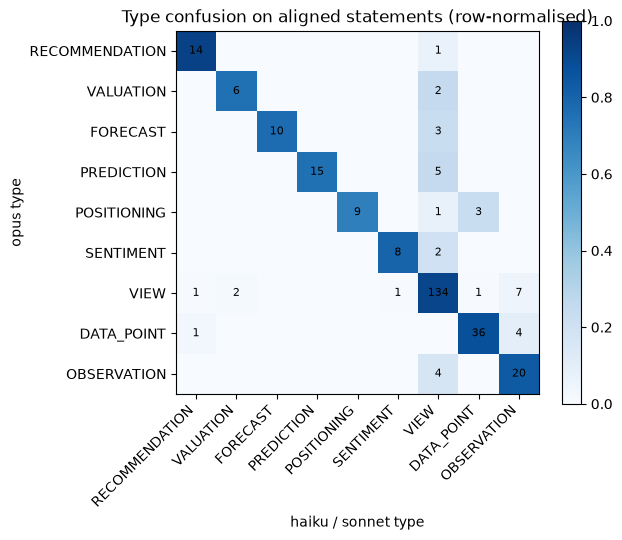

In [ ]:
confusion = pd.crosstab(
    aligned["cluster_pivot_claim_type"], aligned["claim_type"], rownames=["opus type"], colnames=["run type"]
).reindex(index=TYPES, columns=TYPES, fill_value=0)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(confusion.div(confusion.sum(axis=1), axis=0).fillna(0), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(TYPES)), TYPES, rotation=45, ha="right")
ax.set_yticks(range(len(TYPES)), TYPES)
for (i, j), n in pd.DataFrame(confusion.to_numpy()).stack().items():
    if n:
        ax.text(j, i, n, ha="center", va="center", fontsize=8)
ax.set_xlabel("haiku / sonnet type")
ax.set_ylabel("opus type")
ax.set_title("Type confusion on aligned statements (row-normalised)")
fig.colorbar(im, ax=ax)
plt.tight_layout()

In [ ]:
# Off-diagonal pairs by rows and by distinct statements (clusters).
off = aligned[aligned["claim_type"] != aligned["cluster_pivot_claim_type"]]
pair = off["cluster_pivot_claim_type"] + " -> " + off["claim_type"]
pairs = pd.DataFrame({
    "rows": pair.value_counts(),
    "clusters": off.groupby(pair)["cluster_id"].nunique(),
    "docs": off.groupby(pair)["doc"].nunique(),
}).sort_values("rows", ascending=False)
pairs["rows_share"] = (pairs["rows"] / pairs["rows"].sum()).round(2)
display(pairs)
# Type sets assigned to the same statement across the three models.
claims.dropna(subset=["cluster_id"]).groupby("cluster_id")["claim_type"].agg(
    lambda s: "|".join(sorted(set(s)))
).loc[lambda s: s.str.contains("|", regex=False)].value_counts().to_frame("clusters")

,rows,clusters,docs,rows_share
VIEW -> OBSERVATION,7,7,2,0.18
PREDICTION -> VIEW,5,5,3,0.13
OBSERVATION -> VIEW,4,4,2,0.11
DATA_POINT -> OBSERVATION,4,4,3,0.11
POSITIONING -> DATA_POINT,3,2,1,0.08
FORECAST -> VIEW,3,3,1,0.08
SENTIMENT -> VIEW,2,2,2,0.05
VIEW -> VALUATION,2,2,2,0.05
VALUATION -> VIEW,2,2,2,0.05
POSITIONING -> VIEW,1,1,1,0.03


,clusters
claim_type,
OBSERVATION|VIEW,11
PREDICTION|VIEW,5
VALUATION|VIEW,4
DATA_POINT|OBSERVATION,4
SENTIMENT|VIEW,3
FORECAST|VIEW,3
DATA_POINT|POSITIONING,2
RECOMMENDATION|VIEW,2
DATA_POINT|VIEW,1


In [ ]:
cue_words = claims["modality_cue"].str.split().str.len()
display(cue_words.groupby([claims["model"], claims["modality"]]).median().unstack())
exclusions.groupby("model")["code"].value_counts().unstack(fill_value=0)

modality,ASSERTED,HEDGED,SPECULATIVE
model,,,
haiku,5.0,3.0,3.0
opus,2.0,1.0,1.0
sonnet,2.0,1.0,1.0


code,META,NON_CLAIM,NOT_LOAD_BEARING,REDUNDANT,TANGENTIAL,TRANSIENT,VAGUE
model,,,,,,,
haiku,14,5,26,12,0,6,1
opus,8,7,26,0,2,0,5
sonnet,0,0,2,1,1,0,0


### Observations

**More categories, no loss of agreement.** Type agreement is about the same as in the v0.6 round (85%), despite 9 types instead of 6.

| Measure | v0.8 |
|---|---|
| Agreement with opus | haiku 0.85, sonnet 0.91 |
| Pairwise type agreement | sonnet–opus 0.91, haiku–opus 0.85, haiku–sonnet 0.80 (min 0.67 on FOMC) |
| Statement overlap with sonnet | 0.34–0.39, because sonnet extracts about ¼ as many statements |
| Off-diagonal rows | 39 |

- **FORECAST ↔ VIEW is largely resolved.** It caused 45% of all disagreement under v0.6; now it is 3 clusters (8% of off-diagonal rows). Hike predictions moved to PREDICTION in all three models.
- **Remaining confusion, by distinct statements:**

| Pair | Clusters | Nature |
|---|---|---|
| OBSERVATION ↔ VIEW | 11 | Persists from v0.6: characterisations of recent events |
| PREDICTION ↔ VIEW | 5 | Hedged or relative events ("likely to deliver a hawkish hike", "Riksbank will lag the ECB") and author assumptions |
| VALUATION ↔ VIEW | 4 | "Priced / underpriced" judgements on market pricing |
| DATA_POINT ↔ OBSERVATION | 4 | Dates and deadlines; facts mixed with numbers |
| SENTIMENT ↔ VIEW | 3 | Whose mood ("appetite for escalation"), hedged market reactions |
| FORECAST ↔ VIEW | 3 | Scenario-conditional yield reactions; "USD sideways into year-end" with no value |
| DATA_POINT ↔ POSITIONING | 2 | Investor flow figures |

- **Stability with opus by type:** RECOMMENDATION 0.93, VIEW 0.92, DATA_POINT 0.88, OBSERVATION 0.83, SENTIMENT 0.80, FORECAST 0.77, PREDICTION 0.75, VALUATION 0.75, POSITIONING 0.69. The new types are less stable than the old ones, but each has only 14–43 statements.
- **VIEW is still the bulk** (48–56% of statements). Each new type takes 1–6%. The type mix is document-driven:
  - FOMC preview: 15% FORECAST, 13% PREDICTION.
  - Beam: 11% RECOMMENDATION (model portfolio).
  - BofA Liquid Insight: 8% SENTIMENT, 6% POSITIONING.
  - BC_FX: 67% VIEW.
- **Modality by type:**
  - VALUATION is 71% HEDGED.
  - FORECAST splits about a third each between asserted, hedged and speculative, because it is scenario-heavy.
  - PREDICTION is 56% ASSERTED.
- **Cues are shorter than in round 1.** Median cue length for opus and sonnet is 1–2 words, haiku 3–5. In round 1 they were 3–9 words.

## 4. FORECAST (strict)

**Definition (v0.8):** *The author's expectation of a quantitatively measurable outcome, stated with a prospective value and a time horizon.* Discrete events such as hikes, cuts and holds are PREDICTION. Direction-only statements, changes in likelihood, risks, catalysts, conditional scenarios and counterfactuals are VIEW.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `subject` | entity / variable / instrument | One identifiable subject per forecast? |
| `outcome_kind` | level, range, change | Do policy decisions still leak in from PREDICTION? |
| `quantity` | value or min/max, unit, comparator | **Required.** Do the models comply? |
| `horizon` | relation (by, during, within, at) + value | **Required.** Dates vs events? |
| `condition` | clause or and/or group | Are conditional forecasts still produced? |
| `required_truth` | true / false | Negated forecasts ("we do not expect a cut") |
| `basis` | analyst_forecast, nowcast | |

**Compliance test below:** a statement passes when it has a numeric value **and** a horizon (date or event). The `decision` probe flags policy decisions that v0.8 assigns to PREDICTION.

In [ ]:
forecasts = of_type("FORECAST")
display(pd.crosstab(forecasts["label"], forecasts["model"]).reindex(columns=MODELS, fill_value=0))
display(by_model(forecasts, "modality"))
forecasts.sample(min(15, len(forecasts)), random_state=0)[SHOW]

model,haiku,sonnet,opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0,1,3
BofA_Sept_FOMC_-_hike_or_bond_spike,9,8,17


modality,ASSERTED,HEDGED,SPECULATIVE
model,,,
haiku,0.33,0.22,0.44
sonnet,0.22,0.44,0.33
opus,0.35,0.35,0.30


,label,model,statement_id,claim_type,modality,modality_cue,statement
676,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S073,FORECAST,HEDGED,would likely,"In a hawkish-presser scenario, 30Y UST yields would fall 5-10bp."
710,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S107,FORECAST,ASSERTED,we see,"The USD will trade more or less sideways into year-end 2026, excluding against JPY."
643,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S040,FORECAST,HEDGED,likely,"The 2027 SEP median dot will show one cut, to 3.875%."
618,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S015,FORECAST,SPECULATIVE,could,"Without a September hike, the US 30Y yield could rise toward 5.75%."
589,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S071,FORECAST,ASSERTED,We also expect,The 2027 headline and core inflation projections will be revised down 0.1pp.
674,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S071,FORECAST,SPECULATIVE,might guess,"In a hawkish-presser scenario, priced total hikes would reach 100bp, with 60-65bp by end-2026."
685,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S082,FORECAST,ASSERTED,to decline,"In a Fed-hold scenario, priced total hikes would decline to 65-75bp, with 30-35bp by end-2026."
588,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S070,FORECAST,HEDGED,we would expect,"If PCE revisions are incorporated, 2026 headline and core inflation projections fall roughly 30bp."
681,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S078,FORECAST,HEDGED,would likely,"In a dovish-presser scenario, 30Y UST yields would rise 5bp."
85,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S086,FORECAST,HEDGED,implies,"Annualized 2026 overseas investment through NISA implies JPY selling of JPY14.1trn, up JPY3.4trn y/y."


In [ ]:
MONTHS = r"January|February|March|April|June|July|August|September|October|November|December"
FORECAST_PROBES = {
    "number": r"\d",
    "percent_bp": r"%|(?:\d\s?|\b)bps?\b|basis points?|(?:\d\s?|\b)pp\b",
    "level_target": r"\b(?:to|at|towards?|reach(?:es|ing)?|around|near)\s+[-+]?[$€£¥]?\d",
    "decision": r"\b(?:hike|hikes|cut|cuts|hold|holds|on hold|pause|ease|tighten|raise|lower)\b",
    "direction_up": r"\b(?:rise|rises|rising|increase\w*|higher|strengthen\w*|appreciat\w*|gain\w*|rall\w*|accelerat\w*)\b",
    "direction_down": r"\b(?:fall|falls|falling|decline\w*|lower|weaken\w*|depreciat\w*|drop\w*|slow\w*)\b",
    "horizon_date": rf"\b(?:20\d\d|Q[1-4]|[12]H\d\d|FY\d{{2,4}}|year[- ]end|end[- ]\d{{4}}|(?:this|next|coming) (?:week|month|quarter|year)s?|{MONTHS})\b",
    "horizon_event": r"\b(?:meeting|FOMC|ECB|BoE|BoJ|Fed|MPC|budget|election|auction|release|payrolls|CPI)\b",
    "condition": r"\b(?:if|unless|provided|assuming|in the event|once)\b",
    "negation": r"\b(?:not|no|never|unlikely|without)\b|n't",
    "likelihood": r"\b(?:likel\w*|probabilit\w*|chance|odds|risk)\b",
    "third_party": r"\b(?:consensus|according to|markets? (?:expect|pric)\w*|investors expect)\b",
}
fc_hits = probe(forecasts, FORECAST_PROBES)
forecasts = forecasts.assign(
    has_value=fc_hits["number"],
    has_horizon=fc_hits["horizon_date"] | fc_hits["horizon_event"],
)
forecasts = forecasts.assign(strict_pass=forecasts["has_value"] & forecasts["has_horizon"])
display(forecasts.groupby("model")[["has_value", "has_horizon", "strict_pass"]].mean().reindex(MODELS).round(2))
fill_rates(forecasts, FORECAST_PROBES)

,has_value,has_horizon,strict_pass
model,,,
haiku,1.00,0.89,0.89
sonnet,0.89,0.67,0.56
opus,1.00,0.80,0.80


model,haiku,opus,sonnet
number,1.00,1.00,0.89
percent_bp,1.00,0.85,0.78
level_target,0.56,0.35,0.22
decision,0.78,0.50,0.44
direction_up,0.11,0.20,0.44
direction_down,0.56,0.30,0.33
horizon_date,0.89,0.70,0.44
horizon_event,0.11,0.40,0.22
condition,0.11,0.05,0.11
negation,0.00,0.05,0.00


In [ ]:
# Forecasts that fail the strict test: v0.8 says these should be PREDICTION or VIEW.
forecasts.loc[~forecasts["strict_pass"], [*SHOW, "has_value", "has_horizon"]].head(30)

,label,model,statement_id,claim_type,modality,modality_cue,statement,has_value,has_horizon
551,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S033,FORECAST,SPECULATIVE,might guess,"Initially, 2Y yields might fall 15-20bps and 30Y yields rise 10-15bps on a hold.",True,False
675,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S072,FORECAST,HEDGED,would likely,"In a hawkish-presser scenario, 2Y UST yields would rise 5-10bp.",True,False
676,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S073,FORECAST,HEDGED,would likely,"In a hawkish-presser scenario, 30Y UST yields would fall 5-10bp.",True,False
680,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S077,FORECAST,HEDGED,would likely,"In a dovish-presser scenario, 2Y UST yields would fall 5bp.",True,False
681,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S078,FORECAST,HEDGED,would likely,"In a dovish-presser scenario, 30Y UST yields would rise 5bp.",True,False
724,BofA_Sept_FOMC_-_hike_or_bond_spike,sonnet,S004,FORECAST,SPECULATIVE,could,In that case the US 30Y yield could rapidly test 5.75% and UST buybacks would be futile to stop it.,True,False
731,BofA_Sept_FOMC_-_hike_or_bond_spike,sonnet,S011,FORECAST,HEDGED,likely,A hawkish presser would likely see 2Y rates rise 5-10bps and 30Y rates fall 5-10bps.,True,False
732,BofA_Sept_FOMC_-_hike_or_bond_spike,sonnet,S012,FORECAST,HEDGED,likely,A dovish presser would likely see 2Y rates fall 5bps and 30Y rates rise 5bps.,True,False
741,BofA_Sept_FOMC_-_hike_or_bond_spike,sonnet,S021,FORECAST,ASSERTED,we see,The USD will trade more or less sideways into year-end excluding JPY.,False,True


In [ ]:
display(boundary_summary("FORECAST"))
boundary("FORECAST")[["cluster_id", *SHOW]].head(40)

claim_type
VIEW    3
Name: count, dtype: int64

,cluster_id,label,model,statement_id,claim_type,modality,modality_cue,statement
554,BofA_Sept_FOMC_-_hike_or_bond_spike:S015,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S036,VIEW,SPECULATIVE,could rapidly test,"If the Fed does not hike, the US 30Y could rapidly test 5.75%."
618,BofA_Sept_FOMC_-_hike_or_bond_spike:S015,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S015,FORECAST,SPECULATIVE,could,"Without a September hike, the US 30Y yield could rise toward 5.75%."
538,BofA_Sept_FOMC_-_hike_or_bond_spike:S072,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S020,VIEW,HEDGED,This would likely see,A hawkish presser would likely see 2Y rates rise and 30Y rates fall by 5-10bps.
675,BofA_Sept_FOMC_-_hike_or_bond_spike:S072,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S072,FORECAST,HEDGED,would likely,"In a hawkish-presser scenario, 2Y UST yields would rise 5-10bp."
566,BofA_Sept_FOMC_-_hike_or_bond_spike:S107,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S048,VIEW,ASSERTED,we see the USD trading more-or-less sideways,"The USD will trade more-or-less sideways into year-end, ex-JPY."
710,BofA_Sept_FOMC_-_hike_or_bond_spike:S107,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S107,FORECAST,ASSERTED,we see,"The USD will trade more or less sideways into year-end 2026, excluding against JPY."


### Observations

- **The strict definition holds.** 38 FORECASTs, 34 of them in the FOMC preview.
  - Numeric value: 89–100% of rows.
  - Strict pass (value + horizon): haiku 0.89, opus 0.80, sonnet 0.56.
  - There are no bare hike or cut predictions left in FORECAST.
- **"Decision" rows still in FORECAST are numeric paths**, which is defensible:
  - "The 2026 median dot will show 50bp of hikes"
  - "BofA forecasts 75bp of Fed hikes in 2026"
  - Opus split the BoJ cleanly: "BoJ to hike in Sep, Jan, Jul" is PREDICTION, while "BoJ policy rate 1.75% by July 2027" is FORECAST.
- **Most failures of the strict test are scenario-conditional reactions:**
  - "In a hawkish-presser scenario, 2Y UST yields would rise 5–10bp"
  - "If the Fed holds, 30Y would rise 10–15bp"

  These have a value, and their horizon is the event, which the probe misses. Opus and sonnet type them FORECAST and haiku sometimes types them VIEW. v0.8 is ambiguous here: conditional scenarios go to VIEW, but measurable outcomes stated as possibilities go to FORECAST. **Proposed rule:** a quantified reaction under a stated scenario is a FORECAST, with the scenario recorded in `condition`.
- **A true violation:** "The USD will trade more or less sideways into year-end". It has no value, so it should be VIEW. Haiku typed it VIEW; sonnet and opus typed it FORECAST.
- **Forecasts are the most speculative type** (30–44% SPECULATIVE), which follows from the scenario structure.

## 4b. PREDICTION (new, yellow)

**Definition (v0.8):** *The author's expectation that a specific, identifiable future event will or will not happen, where the outcome is verifiable but not a measured quantity.* Policy decisions (hike, cut, hold, end of QT), sized moves ("a 25bp hike in December"), elections, announcements, interventions and expected non-events. Measurable quantities with a value and horizon stay FORECAST; vague developments with no identifiable event are VIEW.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `event_kind` | policy_decision, election, announcement, intervention, default, deal, other | Is the corpus almost all policy decisions? |
| `actor` | Fed, ECB, BoE, BoJ, government, ... | Always named? |
| `event` | hike, cut, hold, end QT, intervene, ... | One event per statement? |
| `size` | 25bp, 50bp | Optional: how often a sized move is given |
| `horizon` | meeting, month, quarter, year | Required? How often absent? |
| `required_truth` | true / false | Expected non-events ("no cut this year") |
| `condition` | clause | Conditional predictions ("if inflation surprises") |
| `likelihood` | likely, unlikely, risk | Overlap with VIEW (changes in likelihood) |

**Checks below:** event kind and horizon fill rates; predictions with no identifiable event (should be VIEW); policy decisions still typed FORECAST (should be PREDICTION).

In [ ]:
predictions = of_type("PREDICTION")
print(f"{len(predictions)} PREDICTION statements")
display(pd.crosstab(predictions["label"], predictions["model"]).reindex(columns=MODELS, fill_value=0))
display(by_model(predictions, "modality"))
predictions[SHOW]

43 PREDICTION statements


model,haiku,sonnet,opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0,0,1
Beam_yields_up__Scotty,3,1,6
BofA_Liquid_Insight_-_France_risks_for_E…,2,0,1
BofA_Sept_FOMC_-_hike_or_bond_spike,9,4,16


modality,ASSERTED,HEDGED,SPECULATIVE
model,,,
haiku,0.43,0.29,0.29
sonnet,0.60,0.40,0.00
opus,0.62,0.25,0.12


,label,model,statement_id,claim_type,modality,modality_cue,statement
30,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S031,PREDICTION,ASSERTED,our forecast,"Barclays expects the BoJ to hike rates in September 2026, January 2027 and July 2027."
166,Beam_yields_up__Scotty,haiku,S024,PREDICTION,HEDGED,it’s unlikely Treasury will accept,Treasury is unlikely to accept $32bn worth of par in offers.
223,Beam_yields_up__Scotty,haiku,S081,PREDICTION,HEDGED,look likely,Further BoJ hikes look likely.
235,Beam_yields_up__Scotty,haiku,S093,PREDICTION,ASSERTED,We see unchanged policy through all of 2026,The SNB will keep policy unchanged through 2026.
285,Beam_yields_up__Scotty,opus,S023,PREDICTION,HEDGED,unlikely,The US Treasury is unlikely to accept $32bn worth of par in buyback offers.
308,Beam_yields_up__Scotty,opus,S046,PREDICTION,ASSERTED,Expect,Warsh's Jackson Hole keynote will include much continued talk of tackling inflation as the primary goal.
362,Beam_yields_up__Scotty,opus,S100,PREDICTION,HEDGED,look likely,The BoJ is likely to deliver further rate hikes.
370,Beam_yields_up__Scotty,opus,S108,PREDICTION,ASSERTED,We see unchanged policy,The SNB will leave policy unchanged through all of 2026.
375,Beam_yields_up__Scotty,opus,S113,PREDICTION,ASSERTED,Hikes are coming,The RBNZ will deliver further rate hikes.
381,Beam_yields_up__Scotty,opus,S119,PREDICTION,ASSERTED,will lag,The Riksbank will lag the ECB and other central banks in raising rates.


In [ ]:
PREDICTION_PROBES = {
    "policy_decision": r"\b(?:hik\w*|cut\w*|hold\w*|on hold|paus\w*|rais\w*|lower\w*|tighten\w*|eas(?:e|es|ing)|QT|QE|taper\w*|balance sheet)\b",
    "sized_move": r"\d+\s?bps?\b|\bbasis points?\b",
    "actor": r"\b(?:Fed|FOMC|ECB|BoE|BoJ|MPC|SNB|RBA|PBoC|NBP|CNB|central banks?|government|Treasury|MoF|parliament|Congress|minister|PM)\b",
    "other_event": r"\b(?:election\w*|vot\w*|appoint\w*|announc\w*|interven\w*|default\w*|downgrad\w*|upgrad\w*|deal|budget|reform\w*|referendum|resign\w*|collapse\w*)\b",
    "horizon": FORECAST_PROBES["horizon_date"] + "|" + FORECAST_PROBES["horizon_event"],
    "negated": FORECAST_PROBES["negation"],
    "likelihood": FORECAST_PROBES["likelihood"],
    "condition": FORECAST_PROBES["condition"],
}
pred_hits = probe(predictions, PREDICTION_PROBES)
predictions = predictions.assign(
    event_kind=pd.Series("none", index=predictions.index)
    .mask(pred_hits["other_event"], "other_event")
    .mask(pred_hits["policy_decision"], "policy_decision")
)
display(pd.crosstab(predictions["model"], predictions["event_kind"]).reindex(MODELS))
display(fill_rates(predictions, PREDICTION_PROBES))
# No identifiable event: v0.8 says these should be VIEW.
predictions.loc[predictions["event_kind"] == "none", SHOW]

event_kind,none,other_event,policy_decision
model,,,
haiku,6,2,6
sonnet,2,0,3
opus,10,1,13


model,haiku,opus,sonnet
policy_decision,0.43,0.54,0.6
sized_move,0.07,0.08,0.2
actor,0.71,0.71,0.6
other_event,0.14,0.04,0.0
horizon,0.57,0.71,0.6
negated,0.07,0.17,0.0
likelihood,0.07,0.08,0.4
condition,0.14,0.08,0.2


,label,model,statement_id,claim_type,modality,modality_cue,statement
166,Beam_yields_up__Scotty,haiku,S024,PREDICTION,HEDGED,it’s unlikely Treasury will accept,Treasury is unlikely to accept $32bn worth of par in offers.
235,Beam_yields_up__Scotty,haiku,S093,PREDICTION,ASSERTED,We see unchanged policy through all of 2026,The SNB will keep policy unchanged through 2026.
285,Beam_yields_up__Scotty,opus,S023,PREDICTION,HEDGED,unlikely,The US Treasury is unlikely to accept $32bn worth of par in buyback offers.
308,Beam_yields_up__Scotty,opus,S046,PREDICTION,ASSERTED,Expect,Warsh's Jackson Hole keynote will include much continued talk of tackling inflation as the primary goal.
370,Beam_yields_up__Scotty,opus,S108,PREDICTION,ASSERTED,We see unchanged policy,The SNB will leave policy unchanged through all of 2026.
408,Beam_yields_up__Scotty,sonnet,S021,PREDICTION,ASSERTED,We see,The SNB is expected to leave policy unchanged through all of 2026.
561,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S043,PREDICTION,ASSERTED,We expect,Bessent and Warsh will effectively explain this tradeoff to Trump.
579,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S061,PREDICTION,HEDGED,will probably say,Warsh will probably say that progress on underlying inflation has been insufficient.
592,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S074,PREDICTION,ASSERTED,We think it will,The Fed will incorporate the PCE methodology changes into its projections.
603,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S085,PREDICTION,SPECULATIVE,might also be altered,The statement might alter its productivity-growth language given soft recent productivity readings.


In [ ]:
# Leakage: policy decisions still typed FORECAST, and where one model says PREDICTION, what the others say.
decision_forecasts = forecasts[fc_hits["decision"] & ~fc_hits["level_target"]]
print(f"{len(decision_forecasts)} FORECAST rows that read like policy decisions")
display(decision_forecasts[SHOW].head(20))
display(boundary_summary("PREDICTION"))
boundary("PREDICTION")[["cluster_id", *SHOW]]

8 FORECAST rows that read like policy decisions


,label,model,statement_id,claim_type,modality,modality_cue,statement
529,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S011,FORECAST,ASSERTED,we expect,The 2026 median dot will show 50bp of hikes this year.
551,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S033,FORECAST,SPECULATIVE,might guess,"Initially, 2Y yields might fall 15-20bps and 30Y yields rise 10-15bps on a hold."
605,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S002,FORECAST,ASSERTED,expect,"The September SEP 2026 median dot will show 50bp of total Fed hikes in 2026, implying another hike in October or December."
616,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S013,FORECAST,ASSERTED,is the first part,"BofA US Economics forecasts 75bp of Fed hikes in 2026, of which the September hike is the first part."
686,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S083,FORECAST,SPECULATIVE,might guess,"In a Fed-hold scenario, 2Y UST yields would initially fall 15-20bp."
687,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S084,FORECAST,SPECULATIVE,might guess,"In a Fed-hold scenario, 30Y UST yields would initially rise 10-15bp."
733,BofA_Sept_FOMC_-_hike_or_bond_spike,sonnet,S013,FORECAST,SPECULATIVE,might,"If the Fed surprisingly holds, 2Y may initially fall 15-20bps and 30Y rise 10-15bps."
737,BofA_Sept_FOMC_-_hike_or_bond_spike,sonnet,S017,FORECAST,ASSERTED,we expect,The 2026 median dot will show 50bp of hikes this year.


claim_type
VIEW    5
Name: count, dtype: int64

,cluster_id,label,model,statement_id,claim_type,modality,modality_cue,statement
192,Beam_yields_up__Scotty:S046,Beam_yields_up__Scotty,haiku,S050,VIEW,ASSERTED,Expect much continued talk,Much continued talk of tackling inflation as the primary goal is expected.
308,Beam_yields_up__Scotty:S046,Beam_yields_up__Scotty,opus,S046,PREDICTION,ASSERTED,Expect,Warsh's Jackson Hole keynote will include much continued talk of tackling inflation as the primary goal.
252,Beam_yields_up__Scotty:S119,Beam_yields_up__Scotty,haiku,S110,VIEW,ASSERTED,will lag the ECB,The Riksbank will lag the ECB in adjusting rates higher.
381,Beam_yields_up__Scotty:S119,Beam_yields_up__Scotty,opus,S119,PREDICTION,ASSERTED,will lag,The Riksbank will lag the ECB and other central banks in raising rates.
444,BofA_Liquid_Insight_-_France_risks_for_EUR:S010,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,S034,PREDICTION,ASSERTED,we work under the assumption,The government presents and passes a budget plan with sufficient corrective action to keep the planned deficit unchanged versus 2026.
465,BofA_Liquid_Insight_-_France_risks_for_EUR:S010,BofA_Liquid_Insight_-_France_risks_for_E…,opus,S010,PREDICTION,ASSERTED,we work under the assumption,The French government will manage to present and pass a 2027 budget plan with sufficient corrective action to keep the planned deficit unchanged vs 2026.
513,BofA_Liquid_Insight_-_France_risks_for_EUR:S010,BofA_Liquid_Insight_-_France_risks_for_E…,sonnet,S016,VIEW,HEDGED,would likely,The government manages to present and pass a budget with sufficient corrective action to keep the deficit unchanged vs 2026.
526,BofA_Sept_FOMC_-_hike_or_bond_spike:S005,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S008,VIEW,HEDGED,likely to deliver,Warsh will likely deliver a hawkish hike.
608,BofA_Sept_FOMC_-_hike_or_bond_spike:S005,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S005,PREDICTION,ASSERTED,We expect,Warsh will deliver a hawkish hike at the September FOMC.
728,BofA_Sept_FOMC_-_hike_or_bond_spike:S005,BofA_Sept_FOMC_-_hike_or_bond_spike,sonnet,S008,PREDICTION,HEDGED,likely,Warsh is likely to deliver a hawkish hike.


### Observations

- **The target case works in all three models.** "The Fed will hike 25bp at the September FOMC" is PREDICTION from haiku, sonnet and opus. So are:
  - "The Fed will hike again in October and December"
  - "The SNB will keep policy unchanged through 2026"
  - "There will be no Fed balance-sheet changes at the September meeting", an expected non-event
- **Scope creep into communication content.** 18 of 43 (42%) name no policy decision or market event. Examples:
  - "Warsh will say progress on underlying inflation has been insufficient"
  - "The FOMC statement might alter its productivity language"
  - "Warsh will be asked why the Fed did not hike in July"
  - "Bessent and Warsh will explain the tradeoff to Trump"

  These are verifiable, but of low investment value, and mostly come from opus. **Decide** between restricting PREDICTION to market-relevant decisions and outcomes, and adding `event_kind: communication`.
- **The ambiguous cases are as predicted** (5 PREDICTION ↔ VIEW clusters):
  - Hedged outcomes: "Warsh is likely to deliver a hawkish hike" (haiku: VIEW).
  - Relative timing: "The Riksbank will lag the ECB in raising rates".
  - Author working assumptions: "we work under the assumption the government passes a budget" (opus and haiku: PREDICTION; sonnet: VIEW). An assumption that conditions the analysis is arguably a condition, not an expectation.
- **Structure.** PREDICTION often sits in `conditions` (20 rows): models use the expected event as the premise of scenario arguments ("if the Fed hikes…"), which fits. Pooled §9 probe rates:
  - Actor named: 0.70.
  - Horizon: 0.65.
  - Negated: 0.12.
  - Sized move: 0.09. Sized moves went to FORECAST, as intended.

## 5. DATA_POINT

**Definition (v0.8):** *A reported or attributed fact that carries a substantive number, or a rating or estimate attributed to a third party.* Fixed modality `ASSERTED`; rationale only. Positioning and flow figures belong to POSITIONING, survey results on investor attitudes to SENTIMENT, and counterfactual estimates to VIEW.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `observation_kind` | measurement, change, event, reported_state | One kind per row? |
| `metric` / `variable` | free text, later a registry id | Recoverable for every row? |
| `value`, `unit` | point or range; %, bp, currency, x | One measurement per row (atomicity)? |
| `period` / `as_of` | date, month, quarter, y/y | |
| `previous_value` / `change` | from→to | |
| `source` / `attributed_to` | agency, consensus, broker | |
| `basis` | reported, market_implied, consensus, third_party_forecast | |

In [ ]:
data_points = of_type("DATA_POINT")
display(pd.crosstab(data_points["label"], data_points["model"]).reindex(columns=MODELS, fill_value=0))
# Fixed modality: anything other than ASSERTED is a rule violation.
display(by_model(data_points, "modality"))
data_points.sample(min(15, len(data_points)), random_state=0)[SHOW]

model,haiku,sonnet,opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0,7,16
Beam_yields_up__Scotty,21,4,19
BofA_Liquid_Insight_-_France_risks_for_E…,5,5,7
BofA_Sept_FOMC_-_hike_or_bond_spike,8,2,11


modality,ASSERTED
model,
haiku,1.0
sonnet,1.0
opus,1.0


,label,model,statement_id,claim_type,modality,modality_cue,statement
159,Beam_yields_up__Scotty,haiku,S017,DATA_POINT,ASSERTED,reaching its highest yield since 2007,The 30-yr yield last week reached its highest level since 2007.
376,Beam_yields_up__Scotty,opus,S114,DATA_POINT,ASSERTED,three fully priced,Three RBNZ hikes are fully priced over the next year.
29,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S030,DATA_POINT,ASSERTED,prices,"The OIS market prices almost quarterly BoJ hikes, taking the policy rate to nearly 1.9% by July 2027."
386,Beam_yields_up__Scotty,opus,S124,DATA_POINT,ASSERTED,use CHF as the funder,"Five of the Machines' six picks use CHF as the funder, and CAD is the preferred long in three."
531,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S013,DATA_POINT,ASSERTED,September (p),The September projections show fed funds midpoints of 4.125 for 2026 and 3.875 for 2027.
277,Beam_yields_up__Scotty,opus,S015,DATA_POINT,ASSERTED,are set to be over $1tr,"US debt interest payments this year are set to exceed $1tr (3.3% of GDP), above the primary deficit of $814bn (2.6% of GDP)."
109,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S002,DATA_POINT,ASSERTED,pushed,Hawkish remarks by BoJ officials including Board Member Takata pushed market pricing for BoJ hikes by year-end from around 40bp in August to 45-50bp in Sept...
700,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S097,DATA_POINT,ASSERTED,there have been,"Since 2007, there have been 74 meetings where hikes were partly priced and the Fed held, mostly with 0-3bp priced and never with more than 10bp."
305,Beam_yields_up__Scotty,opus,S043,DATA_POINT,ASSERTED,is a still healthy 50%,The correlation between the DXY and 2-yr yield changes remains a healthy 50%.
266,Beam_yields_up__Scotty,opus,S004,DATA_POINT,ASSERTED,reaching its highest yield since 2007,The 30-year Treasury yield reached its highest level since 2007 last week.


In [ ]:
DATA_POINT_PROBES = {
    "percent": r"%|per ?cent",
    "bp": r"(?:\d\s?|\b)bps?\b|basis points?",
    "currency_amount": r"[$€£¥]\s?\d|\b(?:bn|mn|billion|million|trillion|trn)\b|\b(?:USD|EUR|JPY|GBP)\s?\d",
    "multiple": r"\d(?:\.\d+)?x\b",
    "period": rf"\b(?:20\d\d|Q[1-4]|[12]H\d\d|FY\d{{2,4}}|y/y|yoy|m/m|mom|q/q|week|month|quarter|{MONTHS})\b",
    "change_from_to": r"\bfrom\b[^.]*\bto\b|\b(?:rose|fell|increased|decreased|climbed|dropped|slipped|jumped)\b",
    "comparator": r"\b(?:above|below|more than|less than|at least|at most|over|under|exceed\w*|record)\b",
    "attribution": r"\b(?:according to|consensus|survey|reported|data show\w*|published|estimates?|forecasts?|expects?)\b",
    "market_implied": r"\b(?:priced|pricing|implied|OIS|futures|swaps?|forwards?)\b",
    "supply_issuance": r"\b(?:supply|issuance|auction\w*|redemption\w*|coupon\w*)\b",
    "positioning_data": r"\b(?:CFTC|IMM|positioning|flows?|open interest|holdings|longs?|shorts?)\b",
}
fill_rates(data_points, DATA_POINT_PROBES)

model,haiku,opus,sonnet
percent,0.26,0.26,0.33
bp,0.18,0.17,0.11
currency_amount,0.26,0.34,0.44
multiple,0.00,0.00,0.00
period,0.47,0.62,0.67
change_from_to,0.03,0.11,0.11
comparator,0.24,0.26,0.39
attribution,0.00,0.02,0.06
market_implied,0.26,0.28,0.17
supply_issuance,0.06,0.04,0.00


In [ ]:
# Atomicity: how many numbers does one DATA_POINT carry?
n_numbers = data_points["statement"].str.count(r"\d+(?:[.,]\d+)?").clip(upper=4).rename("numbers (4 = 4+)")
display(pd.crosstab(data_points["model"], n_numbers).reindex(MODELS))
display(data_points[n_numbers >= 3][SHOW].head(15))
display(boundary_summary("DATA_POINT"))
boundary("DATA_POINT")[["cluster_id", *SHOW]].head(40)

numbers (4 = 4+),0,1,2,3,4
model,,,,,
haiku,7,4,12,4,7
sonnet,0,4,4,6,4
opus,7,8,16,8,14


,label,model,statement_id,claim_type,modality,modality_cue,statement
19,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S020,DATA_POINT,ASSERTED,fell,"USDJPY fell from around 164 to nearly 155 after the end-July coordinated intervention, rebounded to around 160 in early September, and briefly fell into the..."
20,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S021,DATA_POINT,ASSERTED,pushed,Hawkish remarks by BoJ officials including Board Member Takata pushed market pricing of BoJ hikes by year-end from around 40bp in August to 45-50bp in Septe...
60,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S061,DATA_POINT,ASSERTED,reached,"FY27 budget requests reached JPY143.1trn, exceeding the JPY140.6trn combined FY26 supplementary and FY27 initial budget."
70,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S071,DATA_POINT,ASSERTED,narrowed,"On a four-quarter moving average, Japan's net JPY selling narrowed from around JPY20trn last year to roughly JPY10trn as of Q2 2026, reflecting intervention."
72,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S073,DATA_POINT,ASSERTED,has been running,"In recent years, overseas investment has been running at around JPY40trn against a current account surplus of around JPY20trn, leaving net JPY selling of ro..."
82,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S083,DATA_POINT,ASSERTED,totaled,Inflows into NISA-eligible investment trusts were JPY12.6trn in 2024 (JPY11.7trn overseas) and JPY9.9trn in 2025 (JPY9.7trn overseas).
83,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S084,DATA_POINT,ASSERTED,have already reached,"YTD 2026 inflows into NISA-eligible investment trusts have reached JPY11.5trn, including JPY9.4trn into overseas assets."
89,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S090,DATA_POINT,ASSERTED,totaled,"Inward FDI totaled JPY6.9trn in 2025 versus outward FDI of JPY32.6trn, but rose JPY4trn y/y versus a JPY1.1trn rise in outward FDI."
94,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S095,DATA_POINT,ASSERTED,reported,"The MoF conducted a record JPY15.4trn JPY-buying intervention at end-July, taking cumulative 2026 intervention to a record JPY27.1trn."
109,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S002,DATA_POINT,ASSERTED,pushed,Hawkish remarks by BoJ officials including Board Member Takata pushed market pricing for BoJ hikes by year-end from around 40bp in August to 45-50bp in Sept...


claim_type
OBSERVATION       4
POSITIONING       2
VIEW              1
RECOMMENDATION    1
Name: count, dtype: int64

,cluster_id,label,model,statement_id,claim_type,modality,modality_cue,statement
41,BC_FX_Views_-_Structural_JPY_weakness_unchanged:S042,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S042,VIEW,SPECULATIVE,would generate,"A 5-10pp GPIF shift back to domestic assets would generate around JPY16-32trn of one-off JPY buying, comparable with this year's intervention."
117,BC_FX_Views_-_Structural_JPY_weakness_unchanged:S042,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S010,DATA_POINT,ASSERTED,would generate,A 5-10pp shift of GPIF's JPY320trn assets back to domestic assets would generate around JPY16-32trn of JPY buying.
181,Beam_yields_up__Scotty:S032,Beam_yields_up__Scotty,haiku,S039,DATA_POINT,ASSERTED,"in four of the last six years, Japan has seen a surplus",Japan has seen net portfolio flow surpluses into long-term debt in four of the last six years.
294,Beam_yields_up__Scotty:S032,Beam_yields_up__Scotty,opus,S032,POSITIONING,ASSERTED,has seen,Japan has seen a surplus in net portfolio flows into long-term debt in four of the last six years as rising JGB yields attract overseas and domestic investors.
182,Beam_yields_up__Scotty:S033,Beam_yields_up__Scotty,haiku,S040,DATA_POINT,ASSERTED,sold over $50bn in overseas long-term debt,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, a net surplus of over $110bn."
295,Beam_yields_up__Scotty:S033,Beam_yields_up__Scotty,opus,S033,POSITIONING,ASSERTED,actually sold,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, giving a net surplus of over $110bn."
396,Beam_yields_up__Scotty:S033,Beam_yields_up__Scotty,sonnet,S009,DATA_POINT,ASSERTED,actually sold,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, so that money is not going into USTs."
207,Beam_yields_up__Scotty:S091,Beam_yields_up__Scotty,haiku,S065,OBSERVATION,ASSERTED,is now taking a wait-and-see approach,The RBA is taking a wait-and-see approach as unemployment remains elevated.
353,Beam_yields_up__Scotty:S091,Beam_yields_up__Scotty,opus,S091,DATA_POINT,ASSERTED,has raised rates three times,The RBA has raised rates three times and is now taking a wait-and-see approach as unemployment remains elevated.
233,Beam_yields_up__Scotty:S124,Beam_yields_up__Scotty,haiku,S091,RECOMMENDATION,ASSERTED,use CHF as the funder,Five of the Machine's six picks use CHF as the funder.


### Observations

- **Fixed modality is respected** (100% ASSERTED). **Quantified market pricing stays here consistently** ("OIS prices the BoJ near 1.9% by July 2027", "three RBNZ hikes are fully priced"). None of it leaked into SENTIMENT, where the pricing probe fires 0%.
- **Atomicity is worse than in round 1.** The share carrying 3 or more numbers is opus 42% (22/53), sonnet 56% (10/18) and haiku 32% (11/34). Example: "NISA trust inflows were JPY12.6trn in 2024 (JPY11.7trn overseas) and JPY9.9trn in 2025 (JPY9.7trn overseas)". One measurement per claim, or `measurements[]`, is still undecided.
- **Investor flow figures are split with POSITIONING:**
  - "Japanese investors sold over $50bn of overseas long-term debt in H1 2026" is POSITIONING for opus but DATA_POINT for haiku and sonnet.
  - Aggregate national flows (NISA inflows, net JPY selling, FDI) stayed DATA_POINT in every model.
  - **Proposed rule:** flows attributed to a named holder group are POSITIONING; balance-of-payments aggregates are DATA_POINT.
- **Scenario arithmetic.** "A 5–10pp GPIF shift would generate JPY16–32trn of JPY buying" is DATA_POINT for sonnet and VIEW for opus. It is a computed hypothetical, not a reported fact, so treat it like a counterfactual (VIEW).
- **Other boundaries:**
  - DATA_POINT ↔ OBSERVATION (4 clusters): deadlines ("the budget must enter parliament by 6 October"), and facts that mention a number in passing ("the dollar remains subdued despite hike pricing at ~85%").
  - House-model signals: "Five of the Machine's six picks use CHF as the funder" is DATA_POINT for opus and RECOMMENDATION for haiku.

## 6. VALUATION

**Definition (v0.8):** *An assessment of worth relative to market price, fundamentals or another reference point, whether or not the words over- or undervalued are used.* Now includes moves that have gone further than fundamentals justify and asset or collateral coverage.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `assessment` | undervalued (cheap), overvalued (rich), fair_value, unjustified_move, coverage | Did the wider definition add new assessment kinds? |
| `reference_kind` | model, historical, relative, fundamentals, required_compensation, asset_coverage | Is it always stated? |
| `method` | model named by the source | |
| `deviation` | value + unit + direction | Share quantified |
| `reference_level` | stated fair-value level | |

In [ ]:
valuations = of_type("VALUATION")
display(pd.crosstab(valuations["label"], valuations["model"]).reindex(columns=MODELS, fill_value=0))
display(by_model(valuations, "modality"))
valuations[SHOW]

model,haiku,sonnet,opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0,1,1
Beam_yields_up__Scotty,3,0,3
BofA_Liquid_Insight_-_France_risks_for_E…,3,1,2


modality,ASSERTED,HEDGED,SPECULATIVE
model,,,
haiku,0.17,0.67,0.17
sonnet,0.00,1.00,0.00
opus,0.33,0.67,0.00


,label,model,statement_id,claim_type,modality,modality_cue,statement
63,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S064,VALUATION,ASSERTED,is,"The Barclays model implies USDJPY fair value of around 157, indicating USDJPY has undershot."
123,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S016,VALUATION,HEDGED,pointing to,"The model-implied USDJPY fair value is around 157, pointing to some undershooting."
211,Beam_yields_up__Scotty,haiku,S069,VALUATION,HEDGED,looks a maximum outcome,What is priced for UK rates looks a maximum outcome for higher rates.
224,Beam_yields_up__Scotty,haiku,S082,VALUATION,SPECULATIVE,their potential,Further BoJ hikes are an underpriced risk for 2026.
237,Beam_yields_up__Scotty,haiku,S095,VALUATION,ASSERTED,the currency expensive but not overly so,The CHF is expensive but not overly so.
272,Beam_yields_up__Scotty,opus,S010,VALUATION,HEDGED,seems,This week's CAD reaction to the trade dispute is an over-reaction.
367,Beam_yields_up__Scotty,opus,S105,VALUATION,HEDGED,looks a maximum outcome,Current market pricing of BoE rates represents the maximum outcome for higher UK rates.
369,Beam_yields_up__Scotty,opus,S107,VALUATION,ASSERTED,expensive but not overly so,The CHF is expensive but not overly so.
414,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,S004,VALUATION,HEDGED,look reasonably priced for now,French fiscal and political developments look reasonably priced for now in FX.
417,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,S007,VALUATION,HEDGED,this suggests that,Investors are already paying a historically large premium for volatility around the French election.


In [ ]:
VALUATION_PROBES = {
    "cheap_under": r"\b(?:cheap\w*|undervalu\w*|attractive\w*|below fair)\b",
    "rich_over": r"\b(?:rich|richer|richly|overvalu\w*|expensive|above fair)\b",
    "fair": r"\bfair(?:ly)?[- ]valu\w*|\bfair value\b|\bfairly priced\b",
    "unjustified_move": r"\b(?:justif\w*|warrant\w*|overshoot\w*|undershoot\w*|further than|more than fundamentals)\b",
    "coverage": r"\b(?:cover\w*|coverage|backed by|collateral)\b",
    "ref_model": r"\bmodel\w*|\bBEER\b|\bPPP\b|\bDCF\b|\bregression\b",
    "ref_historical": r"\bhistor\w*|\baverage\b|\bpercentile\b|\blong[- ]run\b",
    "ref_relative": r"\b(?:relative to|versus|vs\.?|against|compared|peers?|basket)\b",
    "ref_fundamentals": r"\bfundamental\w*|\bearnings\b|\bP/?E\b|\bEBITDA\b|\bmultiples?\b|\bLTV\b",
    "ref_compensation": r"\bspreads?\b|\bcarry\b|\byields?\b|\bterm premi\w*|\brisk premi\w*",
    "deviation_size": r"\d+(?:\.\d+)?\s?(?:%|bps?\b|sd\b|σ|standard deviations?|x\b)",
    "market_implied": r"\b(?:priced|pricing|implied)\b",
}
fill_rates(valuations, VALUATION_PROBES)

model,haiku,opus,sonnet
cheap_under,0.00,0.00,0.0
rich_over,0.17,0.17,0.0
fair,0.00,0.17,0.5
unjustified_move,0.00,0.00,0.5
coverage,0.00,0.00,0.0
ref_model,0.00,0.17,0.5
ref_historical,0.17,0.17,0.0
ref_relative,0.00,0.00,0.0
ref_fundamentals,0.00,0.00,0.0
ref_compensation,0.00,0.00,0.0


In [ ]:
display(boundary_summary("VALUATION"))
display(boundary("VALUATION")[["cluster_id", *SHOW]])
# Valuation language typed as something else.
valuation_language = probe(claims, {k: VALUATION_PROBES[k] for k in ("cheap_under", "rich_over", "fair", "unjustified_move")}).any(axis=1)
display(pd.crosstab(claims.loc[valuation_language, "model"], claims.loc[valuation_language, "claim_type"]))
claims[valuation_language & (claims["claim_type"] != "VALUATION")][SHOW].head(30)

claim_type
VIEW    6
Name: count, dtype: int64

,cluster_id,label,model,statement_id,claim_type,modality,modality_cue,statement
198,Beam_yields_up__Scotty:S010,Beam_yields_up__Scotty,haiku,S056,VIEW,HEDGED,seems,The CAD reaction this week is an over-reaction.
272,Beam_yields_up__Scotty:S010,Beam_yields_up__Scotty,opus,S010,VALUATION,HEDGED,seems,This week's CAD reaction to the trade dispute is an over-reaction.
224,Beam_yields_up__Scotty:S101,Beam_yields_up__Scotty,haiku,S082,VALUATION,SPECULATIVE,their potential,Further BoJ hikes are an underpriced risk for 2026.
363,Beam_yields_up__Scotty:S101,Beam_yields_up__Scotty,opus,S101,VIEW,ASSERTED,we see their potential as an underpriced risk,The potential for further BoJ hikes is an underpriced risk for 2026.
407,Beam_yields_up__Scotty:S101,Beam_yields_up__Scotty,sonnet,S020,VIEW,HEDGED,look likely,Further BoJ hikes look likely and their potential is an underpriced risk for 2026.
417,BofA_Liquid_Insight_-_France_risks_for_EUR:S023,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,S007,VALUATION,HEDGED,this suggests that,Investors are already paying a historically large premium for volatility around the French election.
478,BofA_Liquid_Insight_-_France_risks_for_EUR:S023,BofA_Liquid_Insight_-_France_risks_for_E…,opus,S023,VALUATION,HEDGED,suggests,Investors are already paying a historically large premium for volatility around the French election.
502,BofA_Liquid_Insight_-_France_risks_for_EUR:S023,BofA_Liquid_Insight_-_France_risks_for_E…,sonnet,S005,VIEW,HEDGED,suggests,Investors are already paying a historically large premium for volatility around the French election.
422,BofA_Liquid_Insight_-_France_risks_for_EUR:S032,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,S012,VALUATION,HEDGED,also suggests that,Other markets suggest France-related risks are at least partly priced.
487,BofA_Liquid_Insight_-_France_risks_for_EUR:S032,BofA_Liquid_Insight_-_France_risks_for_E…,opus,S032,VIEW,HEDGED,suggests,Other markets also suggest that France-related risks are at least partly priced.


claim_type,VALUATION,VIEW
model,,
haiku,1,0
opus,2,4
sonnet,1,1


,label,model,statement_id,claim_type,modality,modality_cue,statement
40,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S041,VIEW,SPECULATIVE,could justify,Current yen rates could justify a 5-10pp GPIF reallocation from foreign to domestic bonds even without political pressure.
62,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S063,VIEW,ASSERTED,warrants attention,The risk that renewed fiscal concerns push JGB term premia higher and weaken the JPY at the same time warrants attention.
64,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S065,VIEW,HEDGED,likely,The USDJPY undershoot likely reflects speculative positioning that may be prone to changes in BoJ and GPIF expectations.
125,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S018,VIEW,ASSERTED,warrants attention,Renewed fiscal concerns pushing JGB term premia higher and weakening the JPY is a risk that warrants attention.
631,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S028,VIEW,ASSERTED,can also point to,"Friday's twist flattening of the Treasury curve is evidence that tighter policy reinforces inflation-fighting credibility, further justifying a hike."


### Observations

- **Classic valuation is consistent but rare** (14 statements in total):
  - "The model-implied USDJPY fair value is around 157, pointing to some undershooting" (sonnet and opus)
  - "The CHF is expensive but not overly so" (haiku and opus)
- **The dominant subtype is now the adequacy of market pricing** (market-implied probe 0.33–1.0):
  - "French fiscal and political developments look reasonably priced in FX" (all three models)
  - "What is priced for UK rates looks a maximum outcome"
  - "Further BoJ hikes are an underpriced risk"
  - "Investors are already paying a historically large premium for volatility"
- **These "priced / underpriced" judgements drive the VALUATION ↔ VIEW disagreement** (4 clusters). The BoJ "underpriced risk" is VALUATION for haiku and VIEW for opus and sonnet; "France risks at least partly priced" is VALUATION for haiku and VIEW for the others. **Proposed rule:** a judgement that market pricing is too high, too low or about right is VALUATION, with `reference_kind: market_pricing`.
- **The new "move went further than justified" rule is applied unevenly.** "This week's CAD reaction is an over-reaction" is VALUATION for opus and VIEW for haiku.
- **Unused here:** asset coverage, σ thresholds and deviation sizes. These samples are macro and FX, not credit.
- **VALUATION is the most hedged type** (71% HEDGED).

## 7. RECOMMENDATION (strict)

**Definition (v0.8):** *Actionable investment advice: a concrete action on a named exposure that the author advises taking, holding or exiting.* Stances ("turn bullish"), "not a reason to" statements and generic advice without a named exposure are VIEW.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `kind` | rating, trade | |
| `action` | initiate, add, reduce, close, maintain, hedge, switch, avoid; buy, sell, open | Which actions occur? |
| `legs[]` | instrument + side (long, short, pay, receive, overweight, underweight) | Multi-leg share (steepeners, baskets) |
| `entry`, `target`, `stop`, `notional` | levels as written | Trade ideas in this set state these: how often? |
| `held_vs_advised` | entered or held vs new advice | |
| `motivation` | supporting claims via argument roles | |

**Compliance test below:** a statement passes when it has an action word **and** a named instrument or exposure.

In [ ]:
recommendations = of_type("RECOMMENDATION")
display(pd.crosstab(recommendations["label"], recommendations["model"]).reindex(columns=MODELS, fill_value=0))
display(by_model(recommendations, "is_core"))
recommendations[SHOW]

model,haiku,sonnet,opus
label,,,
Beam_yields_up__Scotty,13,5,11
BofA_Liquid_Insight_-_France_risks_for_E…,0,1,1


is_core,False,True
model,,
haiku,0.23,0.77
sonnet,0.00,1.00
opus,0.00,1.00


,label,model,statement_id,claim_type,modality,modality_cue,statement
143,Beam_yields_up__Scotty,haiku,S001,RECOMMENDATION,ASSERTED,we remain underweight,We remain underweight the USD in our portfolio.
151,Beam_yields_up__Scotty,haiku,S009,RECOMMENDATION,ASSERTED,We maintain,We maintain a short dollar position versus the euro.
196,Beam_yields_up__Scotty,haiku,S054,RECOMMENDATION,ASSERTED,happy to sit short of dollars,We are happy to sit short of dollars into the Jackson Hole gathering.
197,Beam_yields_up__Scotty,haiku,S055,RECOMMENDATION,ASSERTED,we stay overweight,We stay overweight CAD versus AUD.
209,Beam_yields_up__Scotty,haiku,S067,RECOMMENDATION,ASSERTED,We maintain,We maintain a GBP short versus the EUR.
222,Beam_yields_up__Scotty,haiku,S080,RECOMMENDATION,ASSERTED,We keep,We keep a JPY long versus the CHF.
232,Beam_yields_up__Scotty,haiku,S090,RECOMMENDATION,ASSERTED,is now universal,Boost's preference to fund its ideas in CHF is now universal.
233,Beam_yields_up__Scotty,haiku,S091,RECOMMENDATION,ASSERTED,use CHF as the funder,Five of the Machine's six picks use CHF as the funder.
234,Beam_yields_up__Scotty,haiku,S092,RECOMMENDATION,ASSERTED,is switched into a long CADCHF bias,Boost's short AUDCAD is switched into a long CADCHF bias.
238,Beam_yields_up__Scotty,haiku,S096,RECOMMENDATION,ASSERTED,keeps,Forest holds long USDCHF and long CADCHF.


In [ ]:
RECOMMENDATION_PROBES = {
    "act_initiate_enter": r"\b(?:initiat\w*|enter\w*|open\w*)\b",
    "act_buy_long": r"\b(?:buy\w*|long|add\w*|receiv\w*)\b",
    "act_sell_short": r"\b(?:sell\w*|short\w*|pay(?:s|ing)?)\b",
    "act_maintain": r"\b(?:maintain\w*|reiterat\w*|keep|stay|remain|hold)\b",
    "act_reduce_close": r"\b(?:reduce|trim|take profits?|close|exit|unwind)\b",
    "act_hedge": r"\bhedg\w*",
    "act_avoid": r"\b(?:avoid|stay away)\b",
    "rating": r"\b(?:overweight|underweight|equal[- ]?weight|market[- ]?weight|outperform|underperform)\b",
    "instrument_fx": r"(?-i:\b[A-Z]{3}/?[A-Z]{3}\b)|\b(?:CHF|MYR|CZK|NOK|JPY|MXN|PLN|USD|EUR|GBP)\b",
    "instrument_rates": r"\b\d+[yY]\d*[yY]?\b|\b\d+s\d+s\b|\bbonds?\b|\bJGBs?\b|\bgilts?\b|\bBunds?\b|\bBTPs?\b|\bOATs?\b|\bTreasur\w*|\bswaps?\b|\bOIS\b",
    "instrument_credit_equity": r"\b(?:credit|notes?|SUNs?|equit(?:y|ies)|stocks?|shares)\b",
    "structure": r"\b(?:steepen\w*|flatten\w*|basket|spread|butterfl\w*|options?|calls?|puts?)\b",
    "levels": r"\b(?:entry|target|stop|notional|carry|roll)\b",
    "conditional": r"\b(?:if|unless|on (?:a|any) (?:dip|rally|break))\b",
}
rec_hits = probe(recommendations, RECOMMENDATION_PROBES)
actions = rec_hits.filter(like="act_").any(axis=1)
exposure = rec_hits[["instrument_fx", "instrument_rates", "instrument_credit_equity", "structure"]].any(axis=1)
# A rating names its covered exposure by construction.
recommendations = recommendations.assign(strict_pass=(actions & exposure) | rec_hits["rating"])
display(recommendations.groupby("model")["strict_pass"].mean().reindex(MODELS).round(2))
display(recommendations.loc[~recommendations["strict_pass"], SHOW].head(20))
fill_rates(recommendations, RECOMMENDATION_PROBES)

model
haiku     0.46
sonnet    0.67
opus      0.67
Name: strict_pass, dtype: float64

,label,model,statement_id,claim_type,modality,modality_cue,statement
151,Beam_yields_up__Scotty,haiku,S009,RECOMMENDATION,ASSERTED,We maintain,We maintain a short dollar position versus the euro.
196,Beam_yields_up__Scotty,haiku,S054,RECOMMENDATION,ASSERTED,happy to sit short of dollars,We are happy to sit short of dollars into the Jackson Hole gathering.
232,Beam_yields_up__Scotty,haiku,S090,RECOMMENDATION,ASSERTED,is now universal,Boost's preference to fund its ideas in CHF is now universal.
233,Beam_yields_up__Scotty,haiku,S091,RECOMMENDATION,ASSERTED,use CHF as the funder,Five of the Machine's six picks use CHF as the funder.
240,Beam_yields_up__Scotty,haiku,S098,RECOMMENDATION,ASSERTED,We maintain,We maintain a neutral NZD stance.
247,Beam_yields_up__Scotty,haiku,S105,RECOMMENDATION,ASSERTED,We stay neutral,We stay neutral on the SEK this week.
253,Beam_yields_up__Scotty,haiku,S111,RECOMMENDATION,ASSERTED,We adopt,We adopt a neutral NOK stance for now.
310,Beam_yields_up__Scotty,opus,S048,RECOMMENDATION,ASSERTED,we are happy to sit short of dollars,The author is staying short the dollar into the Jackson Hole symposium.
331,Beam_yields_up__Scotty,opus,S069,RECOMMENDATION,ASSERTED,We maintain a neutral Kiwi stance,The author maintains a neutral stance on the NZD.
335,Beam_yields_up__Scotty,opus,S073,RECOMMENDATION,ASSERTED,We stay neutral,The author stays neutral on the SEK this week.


model,haiku,opus,sonnet
act_initiate_enter,0.00,0.00,0.00
act_buy_long,0.23,0.50,0.33
act_sell_short,0.31,0.58,0.17
act_maintain,0.54,0.33,0.50
act_reduce_close,0.00,0.00,0.00
act_hedge,0.00,0.08,0.17
act_avoid,0.00,0.00,0.00
rating,0.15,0.08,0.17
instrument_fx,0.62,0.75,0.83
instrument_rates,0.00,0.00,0.00


In [ ]:
# Motivation: types and roles of statements in arguments whose core claim is a RECOMMENDATION.
rec_args = memberships[(memberships["core_type"] == "RECOMMENDATION") & (memberships["role"] != "core_claim")]
display(pd.crosstab(rec_args["claim_type"], rec_args["role"]))
display(pd.crosstab(rec_args["model"], rec_args["claim_type"], normalize="index").round(2))
display(boundary_summary("RECOMMENDATION"))
boundary("RECOMMENDATION")[["cluster_id", *SHOW]]

role,catalysts,conditions,rationale,risks,supporting
claim_type,,,,,
DATA_POINT,0,0,10,0,0
OBSERVATION,0,0,18,0,0
POSITIONING,0,0,4,2,1
PREDICTION,0,0,0,1,1
RECOMMENDATION,0,1,0,0,0
SENTIMENT,0,0,3,0,1
VALUATION,0,0,0,0,4
VIEW,3,1,0,9,55


claim_type,DATA_POINT,OBSERVATION,POSITIONING,PREDICTION,RECOMMENDATION,SENTIMENT,VALUATION,VIEW
model,,,,,,,,
haiku,0.10,0.22,0.04,0.02,0.00,0.04,0.04,0.54
opus,0.06,0.15,0.08,0.02,0.00,0.04,0.04,0.60
sonnet,0.12,0.00,0.06,0.00,0.06,0.00,0.00,0.75


claim_type
VIEW          2
DATA_POINT    1
Name: count, dtype: int64

,cluster_id,label,model,statement_id,claim_type,modality,modality_cue,statement
232,Beam_yields_up__Scotty:S120,Beam_yields_up__Scotty,haiku,S090,RECOMMENDATION,ASSERTED,is now universal,Boost's preference to fund its ideas in CHF is now universal.
382,Beam_yields_up__Scotty:S120,Beam_yields_up__Scotty,opus,S120,VIEW,ASSERTED,is now universal,The Boost model now uses CHF to fund all of its ideas.
233,Beam_yields_up__Scotty:S124,Beam_yields_up__Scotty,haiku,S091,RECOMMENDATION,ASSERTED,use CHF as the funder,Five of the Machine's six picks use CHF as the funder.
386,Beam_yields_up__Scotty:S124,Beam_yields_up__Scotty,opus,S124,DATA_POINT,ASSERTED,use CHF as the funder,"Five of the Machines' six picks use CHF as the funder, and CAD is the preferred long in three."
453,BofA_Liquid_Insight_-_France_risks_for_EUR:S041,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,S043,VIEW,ASSERTED,We consider CHF or GBP,CHF or GBP are cleaner expressions to hedge France-related risks than EUR-USD.
496,BofA_Liquid_Insight_-_France_risks_for_EUR:S041,BofA_Liquid_Insight_-_France_risks_for_E…,opus,S041,RECOMMENDATION,ASSERTED,We consider,BofA considers CHF or GBP to be cleaner expressions than EUR-USD to hedge France-related risks.
518,BofA_Liquid_Insight_-_France_risks_for_EUR:S041,BofA_Liquid_Insight_-_France_risks_for_E…,sonnet,S021,RECOMMENDATION,ASSERTED,consider,CHF or GBP are cleaner expressions than EUR-USD to hedge France-related risks.


### Observations

- **Concentrated in one document.** 29 of 31 recommendations come from Beam's model portfolio: "We remain underweight the USD", "We maintain a short dollar position versus the euro", "We keep a JPY long versus the CHF". Stability is the highest of any type (0.93), and nearly all are core claims.
- **Neutral stances.** "We stay neutral on the SEK" and "We adopt a neutral NOK stance" are RECOMMENDATION in all three models. v0.8 says a stance with no concrete action is VIEW, but in a portfolio context "neutral" is a rating (no position). **Proposed rule:** a neutral or flat stance on a named exposure in a portfolio or rating context is RECOMMENDATION with `rating: neutral`.
- **House systematic model signals are unresolved.**
  - Examples: "The Boost model switches short AUDCAD into long CADCHF", "Forest holds long USDCHF".
  - These are mostly RECOMMENDATION, but split with DATA_POINT and VIEW.
  - **Decide** between RECOMMENDATION with `source: house_model` and a separate treatment.
- **Instrument preference without an explicit action.** "CHF or GBP are cleaner expressions than EUR-USD to hedge France risk" is RECOMMENDATION for opus and sonnet and VIEW for haiku.
- **Probe limitation.** The strict-pass rate (0.46–0.67) is a regex limitation: "dollar", "euro" and "neutral" aren't matched as an exposure or action. It doesn't indicate rule violations.
- **Opus rewrites "We" as "The author" in statements.** That is harmless, but cues stay verbatim.

## 8. POSITIONING (narrowed, orange)

**Definition (v0.8, narrowed):** *An assertion about the financial exposure actually held by market participants: the size, direction, concentration or change of their holdings, positions or flows.* Beliefs, attitudes and expectations (bullish, optimistic, nervous) are SENTIMENT; the author's own or advised positions stay RECOMMENDATION; the author's stance is VIEW; consequences such as squeeze risk are VIEW.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `holder` | real_money, hedge_fund, leveraged, cta_systematic, retail, dealer, official, foreign, pension, household; null = market | Is a holder named, and is it never the author? |
| `side` | long, short, overweight, underweight, flat | |
| `measure` | net, gross | |
| `size` + `denominator` | value + unit; "of open interest", "of AUM" | |
| `extremity` | crowded, stretched, extended, light | Evaluation folded into the type, not split to VIEW? |
| `change` | increasing, decreasing, reversal; flows | Stock (holdings) vs flow (buying, selling) |
| `data_source` | cftc, fund_flows, survey, prime_brokerage, client_flow | |
| `as_of` | date / period | |

**Questions:** do the three models agree on what is POSITIONING? What did they type it as instead? Do positioning statements still appear under other types (missed positioning)?

In [ ]:
positioning = of_type("POSITIONING")
print(f"{len(positioning)} POSITIONING statements")
display(pd.crosstab(positioning["label"], positioning["model"]).reindex(columns=MODELS, fill_value=0))
display(by_model(positioning, "modality"))
display(pd.crosstab(positioning["model"], positioning["role_set"]))
positioning[SHOW]

23 POSITIONING statements


model,haiku,sonnet,opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0,0,2
Beam_yields_up__Scotty,5,1,8
BofA_Liquid_Insight_-_France_risks_for_E…,3,1,3


modality,ASSERTED,HEDGED
model,,
haiku,1.00,0.00
sonnet,0.50,0.50
opus,0.85,0.15


role_set,rationale,risks,supporting
model,,,
haiku,7,1,0
opus,10,1,2
sonnet,2,0,0


,label,model,statement_id,claim_type,modality,modality_cue,statement
46,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S047,POSITIONING,ASSERTED,already sold,Japanese life insurers already sold a significant amount of foreign bonds during 2022-23.
75,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S076,POSITIONING,ASSERTED,declined sharply,Speculative JPY positions declined sharply after the July intervention.
185,Beam_yields_up__Scotty,haiku,S043,POSITIONING,ASSERTED,start to actively move out of carry positions,Real money investors started actively moving out of carry positions last week.
186,Beam_yields_up__Scotty,haiku,S044,POSITIONING,ASSERTED,positioning remains overweight,Real money carry positioning remains overweight.
208,Beam_yields_up__Scotty,haiku,S066,POSITIONING,ASSERTED,is currently the most overweight holding among real money investors,AUD is the most overweight holding among real money investors.
214,Beam_yields_up__Scotty,haiku,S072,POSITIONING,ASSERTED,the last month has seen real money buying back their underweight,Real money investors bought back their GBP underweight over the last month.
221,Beam_yields_up__Scotty,haiku,S079,POSITIONING,ASSERTED,they are now net buyers,Real money investors are now net buyers of the EUR.
293,Beam_yields_up__Scotty,opus,S031,POSITIONING,ASSERTED,have turned much less supportive,Japanese investor flows have turned much less supportive of overseas long-term debt.
294,Beam_yields_up__Scotty,opus,S032,POSITIONING,ASSERTED,has seen,Japan has seen a surplus in net portfolio flows into long-term debt in four of the last six years as rising JGB yields attract overseas and domestic investors.
295,Beam_yields_up__Scotty,opus,S033,POSITIONING,ASSERTED,actually sold,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, giving a net surplus of over $110bn."


In [ ]:
POSITIONING_FIELDS = {
    "holder": r"\b(?:real money|hedge funds?|leveraged (?:funds?|accounts?)|asset managers?|CTAs?|systematic|retail|households?|dealers?|banks?|life insurers?|insurers?|pension\w*|GPIF|official|central banks?|foreign(?:ers| investors)?|corporates?|speculat\w*|specs|fund managers?|investors?|clients?)\b",
    "side": r"\b(?:net[- ]long|net[- ]short|longs?|shorts?|overweight|underweight|flat)\b",
    "measure": r"\b(?:net|gross)\b",
    "size": r"[-+]?\d+(?:\.\d+)?\s?(?:%|bn\b|mn\b|trn\b|billion|million|trillion|contracts|percentile|sd\b|σ|x\b)",
    "denominator": r"\b(?:of|as a share of|relative to) (?:open interest|AUM|assets|holdings|market cap|free float|portfolios?)\b",
    "extremity": r"\b(?:crowded|stretched|extended|extreme|light|clean|washed[- ]out|saturated|elevated|record)\b",
    "change": r"\b(?:increas\w*|build\w*|added|adding|reduc\w*|cut\w*|trimm\w*|unwind\w*|revers\w*|cover\w*|rotat\w*|shift\w*|inflows?|outflows?|buying|selling|bought|sold)\b",
    "data_source": r"\b(?:CFTC|IMM|EPFR|surveys?|FMS|prime broker\w*|client flows?|TIC|open interest|flow data|MoF|BoJ flow)\b",
    "as_of": rf"\b(?:last week|this week|week to|as of|since|20\d\d|Q[1-4]|{MONTHS})\b",
    "author_cue": r"\b(?:we|our|us)\b",
}
display(fill_rates(positioning, POSITIONING_FIELDS, by="model"))
pd.concat([positioning[["model", "statement"]], first_match(positioning, POSITIONING_FIELDS)], axis=1).head(30)

model,haiku,opus,sonnet
holder,0.75,0.85,0.5
side,0.38,0.46,0.5
measure,0.12,0.23,0.0
size,0.00,0.08,0.0
denominator,0.00,0.00,0.0
extremity,0.00,0.00,0.0
change,0.25,0.31,0.0
data_source,0.00,0.00,0.0
as_of,0.50,0.54,0.0
author_cue,0.00,0.00,0.0


,model,statement,holder,side,measure,size,denominator,extremity,change,data_source,as_of,author_cue
46,opus,Japanese life insurers already sold a significant amount of foreign bonds during 2022-23.,life insurers,NaN,NaN,NaN,NaN,NaN,sold,NaN,2022,NaN
75,opus,Speculative JPY positions declined sharply after the July intervention.,Speculative,NaN,NaN,NaN,NaN,NaN,NaN,NaN,July,NaN
185,haiku,Real money investors started actively moving out of carry positions last week.,Real money,NaN,NaN,NaN,NaN,NaN,NaN,NaN,last week,NaN
186,haiku,Real money carry positioning remains overweight.,Real money,overweight,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
208,haiku,AUD is the most overweight holding among real money investors.,real money,overweight,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
214,haiku,Real money investors bought back their GBP underweight over the last month.,Real money,underweight,NaN,NaN,NaN,NaN,bought,NaN,NaN,NaN
221,haiku,Real money investors are now net buyers of the EUR.,Real money,NaN,net,NaN,NaN,NaN,NaN,NaN,NaN,NaN
293,opus,Japanese investor flows have turned much less supportive of overseas long-term debt.,investor,long,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
294,opus,Japan has seen a surplus in net portfolio flows into long-term debt in four of the last six years as rising JGB yields attract overseas and domestic investors.,investors,long,net,NaN,NaN,NaN,NaN,NaN,NaN,NaN
295,opus,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, giving a net surplus of over $110bn.",investors,long,net,50bn,NaN,NaN,sold,NaN,2026,NaN


In [ ]:
# Agreement: where one model says POSITIONING, what do the others say?
display(boundary_summary("POSITIONING"))
boundary("POSITIONING")[["cluster_id", *SHOW]]

claim_type
DATA_POINT    3
VIEW          1
Name: count, dtype: int64

,cluster_id,label,model,statement_id,claim_type,modality,modality_cue,statement
178,Beam_yields_up__Scotty:S031,Beam_yields_up__Scotty,haiku,S036,VIEW,ASSERTED,have turned much less supportive,Japanese flows have turned much less supportive.
293,Beam_yields_up__Scotty:S031,Beam_yields_up__Scotty,opus,S031,POSITIONING,ASSERTED,have turned much less supportive,Japanese investor flows have turned much less supportive of overseas long-term debt.
181,Beam_yields_up__Scotty:S032,Beam_yields_up__Scotty,haiku,S039,DATA_POINT,ASSERTED,"in four of the last six years, Japan has seen a surplus",Japan has seen net portfolio flow surpluses into long-term debt in four of the last six years.
294,Beam_yields_up__Scotty:S032,Beam_yields_up__Scotty,opus,S032,POSITIONING,ASSERTED,has seen,Japan has seen a surplus in net portfolio flows into long-term debt in four of the last six years as rising JGB yields attract overseas and domestic investors.
182,Beam_yields_up__Scotty:S033,Beam_yields_up__Scotty,haiku,S040,DATA_POINT,ASSERTED,sold over $50bn in overseas long-term debt,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, a net surplus of over $110bn."
295,Beam_yields_up__Scotty:S033,Beam_yields_up__Scotty,opus,S033,POSITIONING,ASSERTED,actually sold,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, giving a net surplus of over $110bn."
396,Beam_yields_up__Scotty:S033,Beam_yields_up__Scotty,sonnet,S009,DATA_POINT,ASSERTED,actually sold,"Japanese investors sold over $50bn of overseas long-term debt in H1 2026, so that money is not going into USTs."


In [ ]:
# Missed positioning: holdings or flows by a named non-author group, typed as something else.
HOLDINGS = r"\b(?:positioning|positions?|longs|shorts|net (?:long|short)|holdings?|exposures?|allocation\w*|inflows?|outflows?|net (?:buy|sell)\w*|overweight|underweight|crowded|under-?owned|over-?owned)\b"
holder_hit = claims["statement"].str.contains(POSITIONING_FIELDS["holder"], case=False, regex=True, na=False)
holding_hit = claims["statement"].str.contains(HOLDINGS, case=False, regex=True, na=False)
author_hit = claims["statement"].str.contains(r"\b(?:we|our)\b", case=False, regex=True, na=False)
missed = claims[holder_hit & holding_hit & ~author_hit & (claims["claim_type"] != "POSITIONING")]
display(pd.crosstab(missed["model"], missed["claim_type"]).reindex(index=MODELS, fill_value=0))
missed[SHOW].head(30)

claim_type,OBSERVATION,VIEW
model,,
haiku,0,1
sonnet,0,2
opus,2,7


,label,model,statement_id,claim_type,modality,modality_cue,statement
8,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S009,VIEW,SPECULATIVE,could,Expectations-driven JPY appreciation could reverse if no GPIF asset-allocation change is implemented.
36,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S037,OBSERVATION,ASSERTED,had already referred,PM Takaichi and FM Katayama referred to changes in the GPIF's asset allocation in the first half of July.
37,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S038,OBSERVATION,ASSERTED,has sought,"When changing its asset allocation in the past, the GPIF announced the change only after asset transfers were completed, to avoid front-running."
38,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S039,VIEW,ASSERTED,remains unclear,Whether the GPIF will actually decide to change its asset allocation remains unclear.
64,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S065,VIEW,HEDGED,likely,The USDJPY undershoot likely reflects speculative positioning that may be prone to changes in BoJ and GPIF expectations.
74,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S075,VIEW,HEDGED,may,Part of the intervention may have been absorbed by speculative investors' position adjustments.
77,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S078,VIEW,SPECULATIVE,as long as,Active investment outflows from retail investors and corporations continue to exceed Japan's current account surplus.
103,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S104,VIEW,HEDGED,likely,"The US part of the end-July intervention was likely funded from the ESF's foreign-currency holdings, which total USD4.4bn in JPY and EUR."
115,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S008,VIEW,SPECULATIVE,could,The expectations-driven JPY appreciation could reverse if no GPIF asset-allocation change is implemented.
132,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S025,VIEW,HEDGED,will likely,"As long as retail and corporate outflows exceed the current account surplus, structural supply-demand conditions will likely remain a headwind to the JPY."


### Observations

- **The narrowing worked.** All 23 POSITIONING statements describe exposure held by third parties:
  - "The AUD is the most overweight holding among real money investors" (all three models)
  - "Real money investors are now net buyers of the EUR"
  - "Speculative JPY positions declined sharply after the July intervention"
  - "EUR positioning in FX options is neutral"
  - "Japanese life insurers already sold a significant amount of foreign bonds"

  The author cue fires 0%, and no sentiment words (bullish, optimistic) appear: they went to SENTIMENT.
- **Fields are qualitative:**
  - Holder named in 50–85% (real money, life insurers, speculators).
  - Side in 38–50%.
  - Change in up to 31%.
  - Size rarely (0–8%); no denominators or data sources are stated.
  - Extremity words (crowded, stretched) are absent. Authors use relative comparisons instead ("lighter than earlier this year, heavier than into the 2017 election"). **Proposed:** add a `comparison` field rather than `extremity`.
- **Lowest stability of any type (0.69).** It is driven by the flow-figure split with DATA_POINT (§5), and by "Japanese investor flows have turned much less supportive", which opus types POSITIONING and haiku types VIEW.
- **The missed-positioning probe finds mostly correct non-positioning:**
  - The author's causal claims: "the USDJPY undershoot likely reflects speculative positioning" is a VIEW about positioning, not a report of it.
  - Policy statements about GPIF allocation are OBSERVATION.

## 8b. SENTIMENT (new, cyan)

**Definition (v0.8):** *An assertion about the beliefs, attitudes, confidence or expectations of market participants other than the author.* The boundary with VIEW is **whose judgement is described**: the author's own judgement is VIEW whatever its wording ("we are bullish"); investors' mood, fears or expectations are SENTIMENT. Exposure actually held is POSITIONING; quantified market pricing and consensus forecasts of a figure are DATA_POINT.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `holder` | investors, clients, market, hedge funds, consensus; null = market | Is the holder of the belief always named? |
| `attitude` | bullish, bearish, nervous, complacent, optimistic, FOMO | Is a small controlled vocabulary enough? |
| `object` | asset, policy path, macro outcome | What is the belief about? |
| `expectation` | event or level expected by participants | Overlap with PREDICTION / DATA_POINT (market pricing) |
| `change` | improving, deteriorating, turning | |
| `source` | survey, client conversations, pricing, anecdotal | |

**Checks below:** author cues inside SENTIMENT (VIEW leaking in); market-pricing language (DATA_POINT leaking in); participant-mood statements typed as something else (missed sentiment).

In [ ]:
sentiment = of_type("SENTIMENT")
print(f"{len(sentiment)} SENTIMENT statements")
display(pd.crosstab(sentiment["label"], sentiment["model"]).reindex(columns=MODELS, fill_value=0))
display(by_model(sentiment, "modality"))
display(pd.crosstab(sentiment["model"], sentiment["role_set"]))
sentiment[SHOW]

24 SENTIMENT statements


model,haiku,sonnet,opus
label,,,
BC_FX_Views_-_Structural_JPY_weakness_un…,0,0,2
Beam_yields_up__Scotty,4,0,4
BofA_Liquid_Insight_-_France_risks_for_E…,4,1,4
BofA_Sept_FOMC_-_hike_or_bond_spike,2,0,3


modality,ASSERTED,HEDGED
model,,
haiku,0.70,0.30
sonnet,1.00,0.00
opus,0.85,0.15


role_set,conditions,rationale,supporting
model,,,
haiku,0,10,0
opus,1,8,4
sonnet,0,1,0


,label,model,statement_id,claim_type,modality,modality_cue,statement
22,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S023,SENTIMENT,ASSERTED,triggered,The GPIF's unusual August Board of Governors meeting triggered a sharp rise in market expectations that the fund would shift back toward domestic assets.
66,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S067,SENTIMENT,ASSERTED,Persistent,Market concerns about Japanese FX intervention are persistent.
187,Beam_yields_up__Scotty,haiku,S045,SENTIMENT,ASSERTED,real money risk appetite remains positive,Real money risk appetite remains positive.
220,Beam_yields_up__Scotty,haiku,S078,SENTIMENT,ASSERTED,already interprets the ECB as net hawkish,The market already interprets the ECB as net hawkish.
243,Beam_yields_up__Scotty,haiku,S101,SENTIMENT,ASSERTED,a lot is expected from the RBNZ,A lot is expected from the RBNZ in the coming months.
256,Beam_yields_up__Scotty,haiku,S114,SENTIMENT,HEDGED,there appears limited appetite,Appetite for further geopolitical escalation appears limited.
314,Beam_yields_up__Scotty,opus,S052,SENTIMENT,ASSERTED,remains positive,Real money risk appetite remains positive according to the author's broad indicators.
324,Beam_yields_up__Scotty,opus,S062,SENTIMENT,ASSERTED,already interprets,The market already sees the ECB as net hawkish.
330,Beam_yields_up__Scotty,opus,S068,SENTIMENT,ASSERTED,a lot is expected,Market participants expect a lot from the RBNZ in the coming months.
347,Beam_yields_up__Scotty,opus,S085,SENTIMENT,ASSERTED,risk appetite positive,Market risk appetite is positive.


In [ ]:
SENTIMENT_PROBES = {
    "holder": POSITIONING_FIELDS["holder"] + r"|\bmarkets?\b|\bconsensus\b|\bparticipants?\b|\bstreet\b",
    "mood": r"\b(?:sentiment|risk appetite|appetite|nervous\w*|anxi\w*|fear\w*|worr\w*|concern\w*|complacen\w*|confiden\w*|optimis\w*|pessimis\w*|euphori\w*|FOMO|panic\w*|conviction|skeptic\w*|sceptic\w*)\b",
    "stance": r"\b(?:bullish|bearish|cautious|constructive|positive on|negative on)\b",
    "belief_verb": r"\b(?:believ\w*|expect\w*|think\w*|doubt\w*|anticipat\w*|perceiv\w*|view\w*|see|sees)\b",
    "pricing": r"\b(?:pric(?:e|es|ed|ing)|implied|OIS)\b",
    "survey": r"\b(?:survey\w*|poll\w*|FMS)\b",
    "change": r"\b(?:turn\w*|shift\w*|improv\w*|deteriorat\w*|sour\w*|rebound\w*|fad\w*)\b",
    "author_cue": r"\b(?:we|our|us)\b",
}
display(fill_rates(sentiment, SENTIMENT_PROBES, by="model"))
pd.concat([sentiment[["model", "statement"]], first_match(sentiment, SENTIMENT_PROBES)], axis=1).head(30)

model,haiku,opus,sonnet
holder,0.3,0.69,0.0
mood,0.6,0.54,1.0
stance,0.1,0.08,0.0
belief_verb,0.2,0.38,0.0
pricing,0.0,0.00,0.0
survey,0.0,0.08,0.0
change,0.1,0.15,0.0
author_cue,0.0,0.00,0.0


,model,statement,holder,mood,stance,belief_verb,pricing,survey,change,author_cue
22,opus,The GPIF's unusual August Board of Governors meeting triggered a sharp rise in market expectations that the fund would shift back toward domestic assets.,GPIF,NaN,NaN,expectations,NaN,NaN,shift,NaN
66,opus,Market concerns about Japanese FX intervention are persistent.,Market,concerns,NaN,NaN,NaN,NaN,NaN,NaN
187,haiku,Real money risk appetite remains positive.,Real money,risk appetite,NaN,NaN,NaN,NaN,NaN,NaN
220,haiku,The market already interprets the ECB as net hawkish.,market,NaN,NaN,NaN,NaN,NaN,NaN,NaN
243,haiku,A lot is expected from the RBNZ in the coming months.,NaN,NaN,NaN,expected,NaN,NaN,NaN,NaN
256,haiku,Appetite for further geopolitical escalation appears limited.,NaN,Appetite,NaN,NaN,NaN,NaN,NaN,NaN
314,opus,Real money risk appetite remains positive according to the author's broad indicators.,Real money,risk appetite,NaN,NaN,NaN,NaN,NaN,NaN
324,opus,The market already sees the ECB as net hawkish.,market,NaN,NaN,sees,NaN,NaN,NaN,NaN
330,opus,Market participants expect a lot from the RBNZ in the coming months.,Market,NaN,NaN,expect,NaN,NaN,NaN,NaN
347,opus,Market risk appetite is positive.,Market,risk appetite,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Boundary with VIEW and POSITIONING across models, then participant mood typed as something else.
display(boundary_summary("SENTIMENT"))
display(boundary("SENTIMENT")[["cluster_id", *SHOW]])
sent_hits = probe(claims, SENTIMENT_PROBES)
participant_mood = (
    sent_hits["holder"] & (sent_hits["mood"] | sent_hits["stance"] | sent_hits["belief_verb"]) & ~sent_hits["author_cue"]
)
missed_sentiment = claims[participant_mood & (claims["claim_type"] != "SENTIMENT")]
display(pd.crosstab(missed_sentiment["model"], missed_sentiment["claim_type"]).reindex(index=MODELS, fill_value=0))
missed_sentiment[SHOW].head(30)

claim_type
VIEW    3
Name: count, dtype: int64

,cluster_id,label,model,statement_id,claim_type,modality,modality_cue,statement
256,Beam_yields_up__Scotty:S075,Beam_yields_up__Scotty,haiku,S114,SENTIMENT,HEDGED,there appears limited appetite,Appetite for further geopolitical escalation appears limited.
337,Beam_yields_up__Scotty:S075,Beam_yields_up__Scotty,opus,S075,VIEW,HEDGED,there appears limited appetite,There is likely limited appetite for further geopolitical escalation.
446,BofA_Liquid_Insight_-_France_risks_for_EUR:S026,BofA_Liquid_Insight_-_France_risks_for_E…,haiku,S036,VIEW,ASSERTED,does not particularly stand out,"EUR-USD sentiment and positioning do not particularly stand out relative to the periods before the 2017 election, the 2024 National Assembly elections and B..."
481,BofA_Liquid_Insight_-_France_risks_for_EUR:S026,BofA_Liquid_Insight_-_France_risks_for_E…,opus,S026,SENTIMENT,ASSERTED,remains neutral,EUR-USD sentiment remains neutral vs history and does not particularly stand out relative to the periods heading into the 2017 presidential election and the...
503,BofA_Liquid_Insight_-_France_risks_for_EUR:S026,BofA_Liquid_Insight_-_France_risks_for_E…,sonnet,S006,SENTIMENT,ASSERTED,remains,EUR-USD sentiment is neutral versus history and does not stand out relative to the run-ups to the 2017 and 2024 elections.
575,BofA_Sept_FOMC_-_hike_or_bond_spike:S115,BofA_Sept_FOMC_-_hike_or_bond_spike,haiku,S057,VIEW,HEDGED,may not have the patience,Markets may not have the patience for a 'one and done' type event.
718,BofA_Sept_FOMC_-_hike_or_bond_spike:S115,BofA_Sept_FOMC_-_hike_or_bond_spike,opus,S115,SENTIMENT,HEDGED,may,Markets may not have patience for anything sounding like a 'one and done' hike under 'no forward guidance'.


claim_type,FORECAST,OBSERVATION,VIEW
model,,,
haiku,0,1,5
sonnet,1,0,6
opus,0,0,16


,label,model,statement_id,claim_type,modality,modality_cue,statement
4,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S005,VIEW,HEDGED,likely,"The recent sharp JPY appreciation was driven by BoJ rate-hike expectations, technical factors and FX supply-demand, including anticipation of pension funds ..."
5,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S006,VIEW,SPECULATIVE,could,"The recent JPY appreciation could unwind sharply, taking USDJPY back towards the upper-150s, if neither hawkish BoJ hike expectations nor pension repatriati..."
8,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S009,VIEW,SPECULATIVE,could,Expectations-driven JPY appreciation could reverse if no GPIF asset-allocation change is implemented.
10,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S011,VIEW,HEDGED,likely,USDJPY is likely to swing both ways in the near term depending on BoJ and GPIF expectations.
26,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S027,VIEW,SPECULATIVE,could,Market expectations for faster BoJ hikes could start to fade if USDJPY breaks below 150.
47,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S048,VIEW,ASSERTED,we do not expect,Little JPY buying is expected from life insurers' foreign bond sales.
48,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S049,VIEW,HEDGED,may,Life insurers may see current JPY strength as an opportunity to re-engage in JPY selling via FX-unhedged foreign bonds.
64,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S065,VIEW,HEDGED,likely,The USDJPY undershoot likely reflects speculative positioning that may be prone to changes in BoJ and GPIF expectations.
87,BC_FX_Views_-_Structural_JPY_weakness_un…,opus,S088,VIEW,ASSERTED,is expected,Japanese corporate overseas M&A expansion is expected to continue at roughly the same pace in 2026.
108,BC_FX_Views_-_Structural_JPY_weakness_un…,sonnet,S001,VIEW,HEDGED,likely,"The recent sharp JPY appreciation was likely driven by BoJ rate hike expectations, technical factors and FX supply-demand including anticipation of pension ..."


### Observations

- **The "whose judgement" test is applied cleanly.** All 24 SENTIMENT statements describe other participants' beliefs, and the author cue fires 0%:
  - "Real money risk appetite remains positive"
  - "The market already sees the ECB as net hawkish"
  - "EUR-USD sentiment remains meaningfully less bullish than before the Iran war" (survey)
  - "Dollar sentiment has soured since Warsh's July press conference"
  - "Investors expect a meaningful pickup in volatility in the election window"
- **The boundary with VIEW holds from the other side too.** The missed-sentiment probe mainly finds the author's causal claims that mention expectations, such as "the JPY appreciation was driven by BoJ hike expectations". The object there is the author's explanation, so VIEW is correct.
- **Disagreements** (3 SENTIMENT ↔ VIEW clusters, stability 0.80):
  - **Whose appetite:** "Appetite for further geopolitical escalation appears limited" concerns governments, not market participants (opus: VIEW, correct).
  - **Hedged market reaction:** "Markets may not have patience for a one-and-done hike". A conditional expectation of how markets will respond.
  - **Mixed statements:** sentiment and positioning in one sentence; atomicity should split them.
- **Edge cases needing rules:**
  - **Policymakers:** "Many policymakers will likely assume higher rates quell inflation" is SENTIMENT for haiku. Officials are not market participants, so restrict SENTIMENT to investors, traders, clients and markets.
  - **Market expectations of an event:** "The market widely expects the Fed to hike 25bp" (opus: SENTIMENT) overlaps PREDICTION, which needs the author's expectation, and DATA_POINT, which needs quantified pricing. Qualitative, so SENTIMENT is defensible.
- **Mostly in the rationale role** (19 of 24): reported mood grounds the author's views.

## 9. Cross-type summary: do the fields discriminate the types?

Every probe set is run over every statement. A field that fires mainly for its own type is a good schema slot; one that fires evenly is generic (time, numbers) or marks a blurred boundary.

claim_type                               RECOMMENDATION  VALUATION  FORECAST  \
probe set      field                                                           
FORECAST       number                              0.00       0.21      0.97   
               percent_bp                          0.00       0.00      0.87   
               level_target                        0.00       0.14      0.37   
               decision                            0.06       0.07      0.55   
               direction_up                        0.00       0.14      0.24   
               direction_down                      0.00       0.00      0.37   
               horizon_date                        0.10       0.14      0.68   
               horizon_event                       0.00       0.29      0.29   
               condition                           0.00       0.00      0.08   
               negation                            0.00       0.14      0.03   
               likelihood                          0.00       0.07      0.13   
               third_party                         0.00       0.07      0.00   
PREDICTION     policy_decision                     0.06       0.07      0.55   
               sized_move                          0.00       0.00      0.58   
               actor                               0.00       0.14      0.29   
               other_event                         0.00       0.14      0.03   
               horizon                             0.10       0.36      0.79   
               negated                             0.00       0.14      0.03   
               likelihood                          0.00       0.07      0.13   
               condition                           0.00       0.00      0.08   
DATA_POINT     percent                             0.00       0.00      0.24   
               bp                                  0.00       0.00      0.58   
               currency_amount                     0.00       0.00      0.08   
               multiple                            0.00       0.00      0.00   
               period                              0.10       0.14      0.66   
               change_from_to                      0.00       0.00      0.00   
               comparator                          0.00       0.14      0.05   
               attribution                         0.00       0.00      0.11   
               market_implied                      0.00       0.50      0.08   
               supply_issuance                     0.00       0.00      0.05   
               positioning_data                    0.55       0.00      0.00   
VALUATION      cheap_under                         0.00       0.00      0.00   
               rich_over                           0.00       0.14      0.00   
               fair                                0.00       0.14      0.00   
               unjustified_move                    0.00       0.07      0.00   
               coverage                            0.00       0.00      0.00   
               ref_model                           0.06       0.14      0.00   
               ref_historical                      0.00       0.14      0.03   
               ref_relative                        0.39       0.00      0.03   
               ref_fundamentals                    0.00       0.00      0.00   
               ref_compensation                    0.00       0.00      0.24   
               deviation_size                      0.00       0.00      0.82   
               market_implied                      0.00       0.50      0.08   
RECOMMENDATION act_initiate_enter                  0.00       0.00      0.00   
               act_buy_long                        0.35       0.00      0.08   
               act_sell_short                      0.39       0.14      0.03   
               act_maintain                        0.45       0.00      0.16   
               act_reduce_close                    0.00       0.00      0.00   


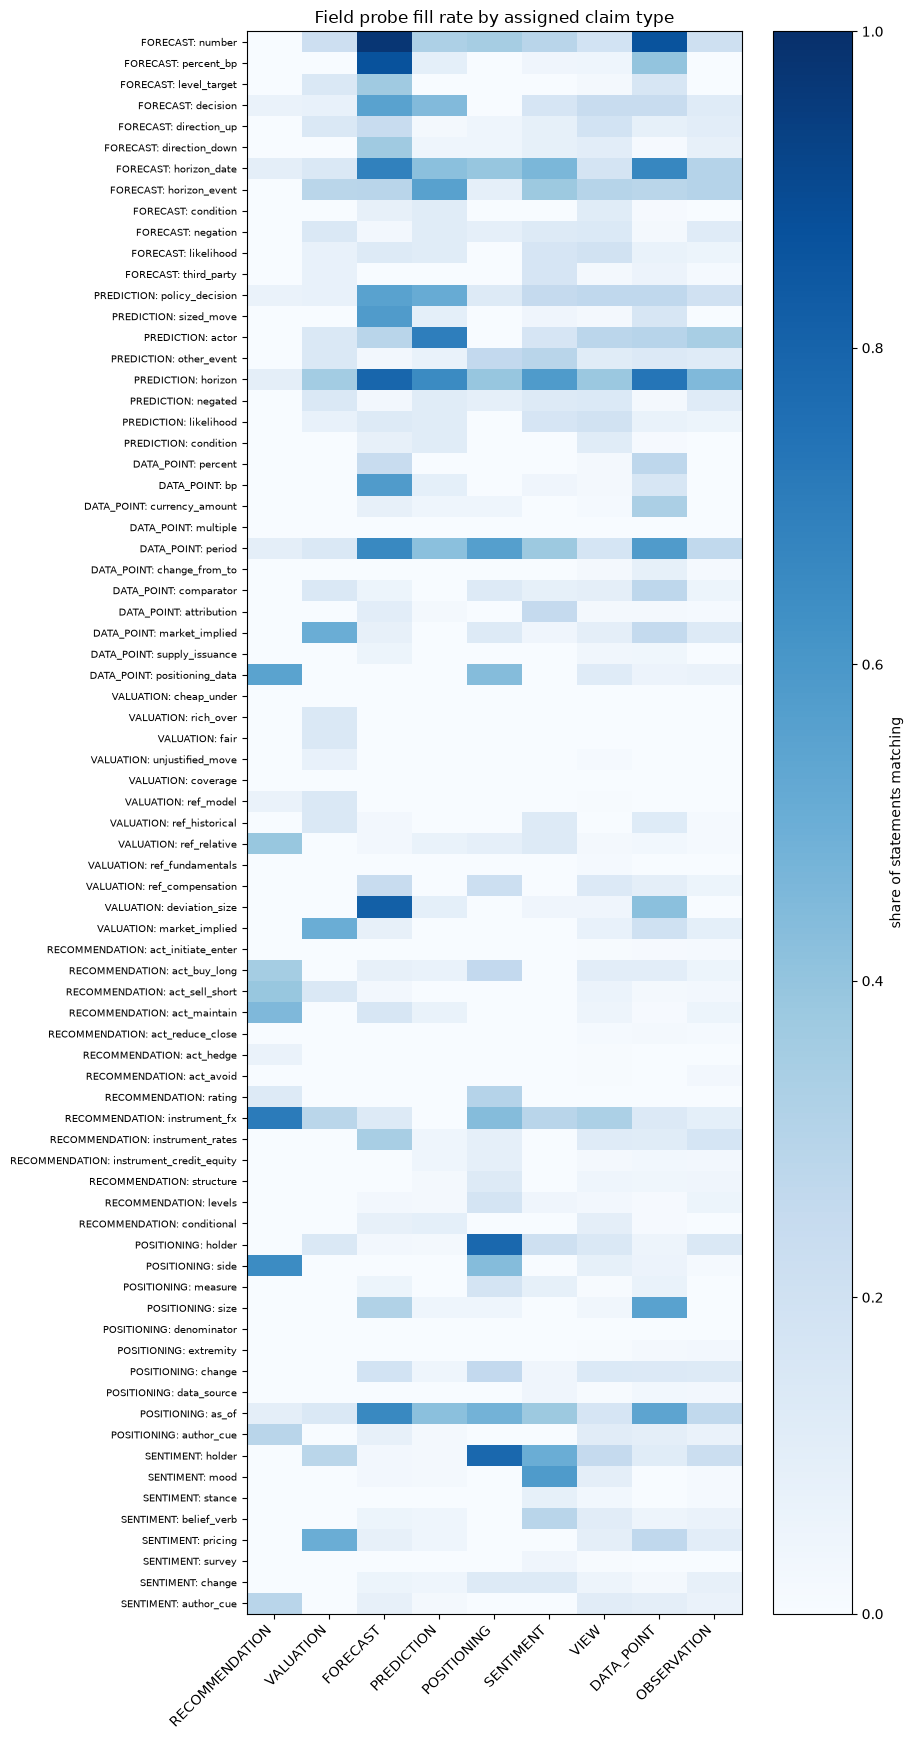

In [ ]:
ALL_PROBES = {
    "FORECAST": FORECAST_PROBES,
    "PREDICTION": PREDICTION_PROBES,
    "DATA_POINT": DATA_POINT_PROBES,
    "VALUATION": VALUATION_PROBES,
    "RECOMMENDATION": RECOMMENDATION_PROBES,
    "POSITIONING": POSITIONING_FIELDS,
    "SENTIMENT": SENTIMENT_PROBES,
}
matrix = pd.concat(
    {owner: probe(claims, patterns).groupby(claims["claim_type"]).mean().T for owner, patterns in ALL_PROBES.items()},
    names=["probe set", "field"],
).reindex(columns=TYPES)

fig, ax = plt.subplots(figsize=(9, 0.22 * len(matrix) + 1))
im = ax.imshow(matrix.fillna(0).to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matrix)), [f"{owner}: {field}" for owner, field in matrix.index], fontsize=7)
fig.colorbar(im, ax=ax, label="share of statements matching")
ax.set_title("Field probe fill rate by assigned claim type")
plt.tight_layout()
matrix.round(2)

### Observations

- **Each new type has a field that fires mainly for it:**
  - PREDICTION: `actor` 0.70 and `policy_decision` 0.51.
  - POSITIONING: `holder` 0.78.
  - SENTIMENT: `mood` 0.58 (VIEW 0.10, about 0 elsewhere).
  - FORECAST: `percent_bp` 0.87 and `deviation_size` 0.82.
- **The number separates FORECAST from PREDICTION.** Both hit `policy_decision` (0.55 vs 0.51), but `sized_move` fires 0.58 for FORECAST and 0.09 for PREDICTION. The quantity, not the topic, is the boundary, as intended.
- **`holder` is shared by POSITIONING (0.78) and SENTIMENT (0.50).** The object separates them: `side` and `change` versus `mood` and `belief_verb`. Keep `holder` as a common field.
- **Trade vocabulary is still shared.** `side` fires 0.65 for RECOMMENDATION and 0.43 for POSITIONING; the holder (the author versus others) is the discriminator.
- **VALUATION's signature has moved.** `market_implied` (0.50) now dominates, and classic cheap/rich/fair words are rare: the pricing-adequacy subtype.

**Caveats:** 4 samples, one run per model, opus as the pivot, haiku missing on BC_FX. The new types have 8–24 statements each, so the stability figures are indicative only.

### Schema notes (proposed from this round)

| Type | Keep / merge / split | Required fields | Optional fields | Open boundary / rule to add |
|---|---|---|---|---|
| FORECAST | Keep | variable, value or range, unit, horizon (date or event) | condition (scenario), direction, basis | Quantified reaction under a stated scenario is FORECAST with `condition`; no value means VIEW |
| PREDICTION | Keep; consider narrowing | actor, event, horizon | size, required_truth, condition, event_kind | Communication-content predictions; author working assumptions (condition, not expectation) |
| DATA_POINT | Keep | metric, value, unit, period | previous_value, source, basis | One measurement per claim; computed hypotheticals are VIEW; holder-attributed flows are POSITIONING |
| VALUATION | Keep; add pricing-adequacy subtype | subject, assessment, reference_kind | deviation, method, reference_level | "Priced / underpriced / reasonably priced" is VALUATION with `reference_kind: market_pricing` |
| RECOMMENDATION | Keep | action or rating, instrument or legs | held_vs_advised, source (author / house model), horizon | Neutral portfolio stance is `rating: neutral`; house systematic model signals |
| POSITIONING | Keep (narrow) | holder, side or change | size, comparison, as_of, data_source | Holder-attributed flow figures here, national aggregates in DATA_POINT |
| SENTIMENT | Keep | holder (market participants only), attitude or expectation | object, change, source (survey) | Exclude policymakers; qualitative market expectations of events stay SENTIMENT |